# Flux: Ecosystem respiration (RECO) (2004-2025)

# About this notebook

Overview of the ecosystem respiration (`RECO`) of CH-LAE, 2004 to 2025, from the merged flux record
`30_FLUX_POST-PROCESSING_CHAIN/99_FPPC_MERGED_2004-2026.09`. This notebook computes and corrects
nothing; it describes what the flux chain produced.

**RECO is modelled, not measured.** The eddy-covariance system measures `NEE` only. At night there is
no photosynthesis, so measured nighttime `NEE` is the respiration of the ecosystem. The nighttime
partitioning (Reichstein et al. 2005, as implemented in ONEFlux and ported to diive) fits the
Lloyd and Taylor (1994) model to measured nighttime `NEE` and air temperature, and evaluates the model
at every half-hour, day and night. `RECO` therefore has no measured series of its own and no
gap-filling flag. How far each year rests on the measurement is given by the share of nights with
measured `NEE`, see *Coverage of the nighttime NEE*.

**The model.** `RECO = Rref · exp(E0 · (1 / (Tref − T0) − 1 / (TA − T0)))`, with `Tref` = 15 °C and
`T0` = −46.02 °C. The fit runs per calendar year. The temperature sensitivity `E0` is one value per
year, from the short windows in which it is best constrained. With `E0` fixed, the reference
respiration `Rref`, the respiration at 15 °C, is fitted in 8-day windows moved by 4 days and
interpolated to every half-hour.

**Sign convention and units.** `RECO` is positive. Half-hourly values are in µmol CO2 m⁻² s⁻¹; sums
are in gC m⁻² (1 µmol m⁻² s⁻¹ over 30 minutes is 0.0216 gC m⁻²).

**Columns used**

- `RECO_NT_OF_CUT_50` — `RECO` from the nighttime partitioning of `NEE` filtered at the median USTAR
  threshold (`CUT_50`). **The main series** and the one used throughout unless stated otherwise
- `RECO_NT_OF_CUT_16`, `RECO_NT_OF_CUT_84` — the same for the other two USTAR scenarios, for the
  USTAR uncertainty
- `RECO_NT_OF_ROB_CUT_50` — the same model with an outlier-robust `Rref`: in each 8-day window the
  5 % of nighttime records farthest from the window mean are dropped before `Rref` is fitted
- `RECO_DT_OF_CUT_50` — `RECO` from the daytime partitioning (Lasslop et al. 2010), an independent
  estimate fitted on daytime `NEE`; for comparison only
- `GPP_NT_OF_CUT_50` — gross primary production of the nighttime partitioning, `RECO − NEE`
- `RREF_NT_OF_CUT_50`, `E0_NT_OF_CUT_50` — the two parameters of the model
- `NEE_L3.1_L3.3_CUT_50_QCF` — measured `NEE` after all quality tests and the USTAR filter, and
  `FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED` (`0` measured, `1` gap-filled)
- `NEE_NIGHT_OF_CUT_50` — the nighttime `NEE` records the fit used. The fit has its own definition
  of night (sun below the horizon and measured shortwave radiation below 10 W m⁻²), slightly
  different from the `NIGHTTIME` flag of the record (potential radiation below 20 W m⁻²)
- `TA_T1_47_1_HOMOGENIZED_MEASURED` — measured air temperature, the temperature of the fit; the
  model is evaluated with the gap-filled temperature, so the plots against temperature leave out
  the gaps of the measured series
- `NIGHTTIME`, `DAYTIME` — day and night flags of the record
- `FLAG_FLUX_SOURCE` — the gas analyser of each half-hour: `75` LI-7500, `72` LI-7200

**Two gas analysers.** The record joins two analysers of different design. The open-path LI-7500
(`IRGA75`) measured from 2004; the enclosed-path LI-7200 (`IRGA72`) from January 2016. The two ran
in parallel until December 2017, and the merged record switches from the LI-7500 to the LI-7200 on
1 January 2016. Each analyser's `NEE` is partitioned on its own, so `RECO` of 2004-2015 is fitted on
LI-7500 nights and `RECO` from 2016 on LI-7200 nights.

::: {.callout-important title="RECO of the LI-7500 years rests on fewer and lower nights"}

The nighttime fit uses measured nighttime `NEE` only. The open-path LI-7500 loses many wet nights
(rain, fog, dew), and on cold nights with fog or rime on its windows it reads `NEE` too low, at times
below zero. The fit follows these nights, so `RECO` of 2004-2015, and with it `GPP`, is likely too
low, most of all in winter. See *Issues* on the documentation site, and the sections on the
temperature response and on the parallel period below.

:::

**Conventions used throughout**

- *Sums, not means.* Annual and monthly values are sums in gC m⁻².
- *USTAR uncertainty* is half the difference between the `CUT_84` and `CUT_16` sums (Pastorello et
  al. 2020). The partitioning has no random uncertainty of its own in the record.
- *Measured nighttime NEE* is used wherever the model is compared with the measurement.

**Timestamps.** The record is stored on `TIMESTAMP_MIDDLE` at 30 minutes in CET (UTC+1), so a
record labelled `13:15` is the average over `13:00` to `13:30`.

</br>

# Settings

In [1]:
# Columns of the merged flux record (30_FLUX_POST-PROCESSING_CHAIN/99).
varname = 'RECO_NT_OF_CUT_50'  # the main series, used unless stated otherwise
SCENARIOS = {'CUT_16': 'RECO_NT_OF_CUT_16',
             'CUT_50': 'RECO_NT_OF_CUT_50',
             'CUT_84': 'RECO_NT_OF_CUT_84'}
varname_rob = 'RECO_NT_OF_ROB_CUT_50'  # outlier-robust Rref
varname_dt = 'RECO_DT_OF_CUT_50'  # daytime partitioning, for comparison
gppname = 'GPP_NT_OF_CUT_50'
rrefname = 'RREF_NT_OF_CUT_50'
e0name = 'E0_NT_OF_CUT_50'
nee_measured = 'NEE_L3.1_L3.3_CUT_50_QCF'  # measured NEE, the data the fit rests on
nee_flag = 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'
nee_fit = 'NEE_NIGHT_OF_CUT_50'  # the nighttime NEE records the fit used
sourcename = 'FLAG_FLUX_SOURCE'
SOURCE_LEGEND = {75: 'LI-7500 (open path, IRGA75)', 72: 'LI-7200 (enclosed path, IRGA72)'}
TA = 'TA_T1_47_1_HOMOGENIZED_MEASURED'
DAYTIME, NIGHTTIME = 'DAYTIME', 'NIGHTTIME'

var = "RECO"  # name shown in plots
units = "µmol m-2 s-1"
units_sum = "gC m-2"
UMOL_TO_GC = 12.011 * 1e-6 * 1800  # umol CO2 m-2 s-1 over one half-hour -> gC m-2

# Period covered by the yearly statistics: the full years of the record. The record runs to
# 30 September 2026; 2026 is incomplete and appears only in the phase overview.
FIRST_YEAR = 2004
LAST_YEAR = 2025

# The phases of the record, as they enter the merged product. Dates are the first day of each phase
# (TIMESTAMP_MIDDLE); a phase ends where the next one begins. Sources: docs/Instrumentation.md,
# docs/L1.md and the setup table in docs/Yearly_Notes.md.
PHASES = [
    ('2004-01-01', 'LI-7500 only', 75,
     'open-path LI-7500; CO2 flux corrected for self-heating (Level 1.1)'),
    ('2016-01-01', 'LI-7200, LI-7500 in parallel', 72,
     'LI-7200 from 11 January 2016 (start-up data of 1 March to 25 May removed); the LI-7500 still '
     'measures and is compared below, but is not used in the product'),
    ('2017-12-13', 'LI-7200, first unit', 72,
     'LI-7500 removed on 12 December 2017; flow module failed 18 May to 7 June 2018'),
    ('2019-01-10', 'no LI-7200 flux', 72,
     'both LI-7200 units defective, then the LI-7500 as a stand-in (not in the product); '
     'no measured NEE in the whole phase'),
    ('2019-03-20', 'LI-7200, second unit', 72,
     'second LI-7200 unit; raw data of 13 December 2021 to 7 February 2022 cannot be converted'),
    ('2023-03-13', 'LI-7200, inlet moved', 72,
     'analyser moved on the boom, which changed its separation from the sonic anemometer'),
    ('2025-12-02', 'LI-7200, recalibrated unit', 72,
     'a freshly calibrated LI-7200 installed'),
]
RECORD_END = '2026-09-30 23:45'

# The two analysers ran in parallel from the start of the LI-7200 to the removal of the LI-7500.
PARALLEL = ('2016-01-11', '2017-12-12')

# The model (diive.flux.partitioning.nighttime_oneflux): Rref is RECO at this temperature, and the
# fit of Rref is bounded below at RREF_FLOOR.
TREF = 15.0  # °C
RREF_FLOOR = 1e-6  # umol m-2 s-1

# Analysis parameters.
N_RECENT_YEARS = 10  # length of the recent period in the trends
N_EXTREMES = 10  # number of days listed in the extremes tables
REFERENCE_START_YEAR = FIRST_YEAR  # reference period for all anomalies
REFERENCE_END_YEAR = LAST_YEAR
LIMITS = (0.0, 30.0)  # physical limits for the integrity check, umol m-2 s-1
RECO_NEAR_ZERO = 0.1  # umol m-2 s-1; below this the model has set respiration to practically zero
NEAR_ZERO_MIN_RECORDS = 24  # a near-zero period is listed when it holds at least this many half-hours
TA_BIN_WIDTH = 2  # °C, bins of the temperature responses
TA_CLASSES = [-30, -5, 0, 5, 10, 15, 20, 40]  # °C, class bounds of the nighttime comparison
# Fixed temperature ranges at which the years are compared, °C (lower bound inclusive).
FIXED_TA = {'below 0 °C': (-30, 0), '4-6 °C': (4, 6), '14-16 °C': (14, 16)}
MIN_RECORDS_BIN = 50  # a temperature bin is shown when it holds at least this many records

# Input files. Data files live in the external (untracked) data folder, mirroring this repo.
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\30_FLUX_POST-PROCESSING_CHAIN")
FILENAME = "99_FPPC_MERGED_2004-2026.09.parquet"
# The per-analyser records, for the parallel period only.
FILE_IRGA75 = r"IRGA75\99_FPPC_IRGA75_MERGED_2004-2017.parquet"
FILE_IRGA72 = r"IRGA72\99_FPPC_IRGA72_MERGED_2016-2026.09.parquet"

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.stats import kendalltau, theilslopes

import diive as dv
from diive.core.plotting.cumulative import CumulativeYear
from diive.core.plotting.bar import LongtermAnomaliesYear

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
version_diive = importlib.metadata.version("diive")
print(f"Last run: {NOTEBOOK_START:%Y-%m-%d %H:%M:%S}")
print(f"diive version: v{version_diive}")

Last run: 2026-10-31 16:50:11
diive version: v0.93.0


# Helpers

In [3]:
def per_year(s, how='mean'):
    """Aggregate `s` to one value per year, indexed by the year number instead of by a timestamp."""
    out = s.resample('YE').agg(how)
    out.index = out.index.year
    out.index.name = 'YEAR'
    return out


def per_year_month(s, how='mean', month_names=True):
    """Aggregate `s` to a table of YEAR (rows) by MONTH (columns)."""
    out = s.groupby([s.index.year, s.index.month]).agg(how).unstack()
    out.index.name = 'YEAR'
    if month_names:
        out.columns = [calendar.month_abbr[m] for m in out.columns]
    return out


def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure drawn with a layout engine makes room for a caption by itself. The figures pandas and
    diive build have no engine, and a caption placed in them lands on top of the tick labels. For
    those the figure is extended downwards by the height of the caption and every axes is moved up
    by the same amount, so the drawing keeps its size and position and the caption gets a free
    strip below it. `width` is the widest the caption may wrap, narrowed for a narrow figure.
    """
    # A fixed wrap width runs off the side of a narrow figure, so it is capped by how many
    # characters of this font size fit across the figure.
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure — {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12  # inches, one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)  # the old figure as a fraction of the new one
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')


def styled(data, caption, fmt="{:.1f}", subset=None, cmap="RdYlBu_r", axis=0, center=False):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values.

    The caption is printed above the table, so it is written as a sentence about what the table
    shows rather than as a title. `center` puts the midpoint of the colour scale at zero, and
    `axis=None` scales the colours across the whole table instead of column by column. The colour
    scale sets a text colour per cell, so the numbers stay readable in both the light and the dark
    version of the rendered page.
    """
    # Formats apply to numbers only, so text columns are dropped from the map. Without this a
    # table carrying a date or a label raises at render time, not at call time.
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        values = data[subset] if subset is not None else data
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def trend(yearly):
    """Theil-Sen slope per decade of a yearly series, with its 95 % interval and Kendall's tau.

    Theil-Sen rather than least squares because a single extreme year does not move it, and
    Kendall's tau because it tests a monotonic trend without assuming normal residuals.
    """
    years = yearly.index.to_numpy(dtype=float)
    values = yearly.to_numpy(dtype=float)
    slope, intercept, low, high = theilslopes(values, years, alpha=0.95)
    tau, pvalue = kendalltau(years, values)
    return dict(slope=slope * 10, low=low * 10, high=high * 10, tau=tau, pvalue=pvalue,
                fit=pd.Series(intercept + slope * years, index=yearly.index))


def longest_spell(mask):
    """Length in days and start date of the longest run of True in a daily boolean series."""
    blocks = mask.ne(mask.shift()).cumsum()
    runs = mask[mask].groupby(blocks[mask]).size()
    if runs.empty:
        return 0, pd.NaT
    return int(runs.max()), mask.index[blocks == runs.idxmax()][0]


def year_axis(ax):
    """Integer year ticks. Matplotlib otherwise labels a numeric year axis with half-years."""
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    return ax


def to_gc(s):
    """Half-hourly flux in umol m-2 s-1 summed to gC m-2 over whatever period `s` covers."""
    return s.sum() * UMOL_TO_GC


def shade_phases(ax, alpha=0.08):
    """Shade the analyser phases behind a time axis and mark their boundaries."""
    colors = ['#1E88E5', '#43A047', '#FB8C00', '#9E9E9E', '#8E24AA', '#00ACC1', '#E53935']
    bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END)]
    for i, (start, end) in enumerate(zip(bounds[:-1], bounds[1:])):
        ax.axvspan(start, end, color=colors[i % len(colors)], alpha=alpha, lw=0)
        ax.axvline(start, color='#616161', lw=0.6, ls=':')


def era(year):
    """The gas analyser of a calendar year in the merged record."""
    return 'LI-7500' if year < 2016 else 'LI-7200'


ERA_COLORS = {'LI-7500': '#1E88E5', 'LI-7200': '#43A047'}
ERAS = (('LI-7500', lambda i: i.year < 2016), ('LI-7200', lambda i: i.year >= 2016))


def binned_median(x, y, bins, min_count=MIN_RECORDS_BIN):
    """Bin centres and medians of `y` in bins of `x`, for bins holding at least `min_count` records."""
    _g = y.groupby(pd.cut(x, bins), observed=True)
    _med = _g.median()[_g.count() >= min_count]
    return np.array([i.mid for i in _med.index]), _med.to_numpy()


def in_range(s, lo, hi):
    """True where `s` lies in [lo, hi)."""
    return (s >= lo) & (s < hi)

</br>

# Load data

In [4]:
# Only the columns this notebook uses are read.
COLUMNS = [*SCENARIOS.values(), varname_rob, varname_dt, gppname, rrefname, e0name, nee_measured,
           nee_flag, nee_fit, TA, DAYTIME, NIGHTTIME, sourcename]
df_full = pd.read_parquet(Path(DATADIR) / FILENAME, columns=COLUMNS)
assert df_full.index.name == 'TIMESTAMP_MIDDLE', f"unexpected index {df_full.index.name}"
print(f"Columns: {df_full.shape[1]}")
print(f"Range:   {df_full.index[0]} -> {df_full.index[-1]} ({len(df_full):,} records)")

# The yearly statistics cover FIRST_YEAR to LAST_YEAR; the phase overview uses the full record.
df = df_full.loc[str(FIRST_YEAR):str(LAST_YEAR)].copy()
series = df[varname].copy()
xlabel = f"{var} ({units})"
print(f"Kept {FIRST_YEAR}-{LAST_YEAR}: {len(df):,} records")

Columns: 15
Range:   2004-01-01 00:15:00 -> 2026-09-30 23:45:00 (398,832 records)
Kept 2004-2025: 385,728 records


## Integrity checks

In [5]:
# The overview describes the record, so it starts by checking what everything below assumes: one
# continuous 30MIN record without duplicates, a complete and non-negative RECO within physical
# limits, complete years, a daytime RECO that is either complete or absent in each year, measured
# NEE where the fill flag says so, the fit's nighttime NEE taken from measured NEE only, one E0 per
# year, and the analyser codes where the merge put them.
_issues = []
if df_full.index.duplicated().any():
    _issues.append("duplicate timestamps")
if not (df_full.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
    _issues.append("index gaps")
for _c in [*SCENARIOS.values(), varname_rob, gppname, rrefname, e0name]:
    if df[_c].isna().any():
        _issues.append(f"{_c}: {int(df[_c].isna().sum())} missing values")
_reco_cols = [*SCENARIOS.values(), varname_rob, varname_dt]
_negative = {c: int((df[c] < 0).sum()) for c in _reco_cols}
if any(_negative.values()):
    _issues.append(f"negative RECO: {_negative}")
if ((series < LIMITS[0]) | (series > LIMITS[1])).any():
    _issues.append(f"values outside {LIMITS}")
_counts = series.groupby(series.index.year).size()
_short = {y: int(n) for y, n in _counts.items() if n != (17568 if calendar.isleap(y) else 17520)}
if _short:
    _issues.append(f"incomplete years: {_short}")
_dt_share = df[varname_dt].notna().groupby(df.index.year).mean()
if not _dt_share.isin([0.0, 1.0]).all():
    _issues.append(f"daytime RECO partly missing in a year: {_dt_share[~_dt_share.isin([0.0, 1.0])].to_dict()}")
if set(df[nee_flag].unique()) - {0, 1}:
    _issues.append(f"unknown fill flags: {sorted(set(df[nee_flag].unique()))}")
if not (df[nee_measured].notna() == df[nee_flag].eq(0)).all():
    _issues.append("fill flag and measured records disagree")
_fit = df[nee_fit].notna()
if not (df.loc[_fit, nee_fit] == df.loc[_fit, nee_measured]).all():
    _issues.append("the fit's nighttime NEE is not measured NEE")
if (df[e0name].groupby(df.index.year).nunique() != 1).any():
    _issues.append("more than one E0 in a year")
if not ((df_full[sourcename] == 75) == (df_full.index < '2016-01-01')).all():
    _issues.append("analyser codes not where the merge put them")

DT_YEARS = [int(y) for y, s in _dt_share.items() if s == 1.0]
print(f"records: {len(df):,}   years: {FIRST_YEAR}-{LAST_YEAR}")
print(f"range:   {series.min():.2g} to {series.max():.1f} {units}")
print(f"negative values per column: {_negative}")
print(f"daytime RECO in: {DT_YEARS[0]}-{DT_YEARS[-1]} "
      f"(missing: {sorted(set(range(FIRST_YEAR, LAST_YEAR + 1)) - set(DT_YEARS))})")
print(f"lowest Rref: {df[rrefname].min():.2g} {units} (the lower bound of the fit is {RREF_FLOOR:g})")
assert not _issues, "the record is not what this overview assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

records: 385,728   years: 2004-2025
range:   1.8e-07 to 14.6 µmol m-2 s-1
negative values per column: {'RECO_NT_OF_CUT_16': 0, 'RECO_NT_OF_CUT_50': 0, 'RECO_NT_OF_CUT_84': 0, 'RECO_NT_OF_ROB_CUT_50': 0, 'RECO_DT_OF_CUT_50': 0}
daytime RECO in: 2005-2025 (missing: [2004])
lowest Rref: 9.5e-07 µmol m-2 s-1 (the lower bound of the fit is 1e-06)
Integrity checks passed.


## Derived series

In [6]:
# Masks and daily sums used throughout, derived once. `daily` holds gC m-2 per day.
is_night = df[NIGHTTIME].eq(1)
is_meas = df[nee_flag].eq(0)
night_meas = is_night & is_meas  # nighttime half-hours with measured NEE
daily = pd.DataFrame({
    'RECO': series.resample('D').sum() * UMOL_TO_GC,
    'RECO_DT': df[varname_dt].resample('D').sum(min_count=1) * UMOL_TO_GC,
    'GPP_NT': df[gppname].resample('D').sum() * UMOL_TO_GC,
    'TA (°C)': df[TA].resample('D').mean(),
    'Rref': df[rrefname].resample('D').median(),
    'measured night (n)': night_meas.resample('D').sum(),
})
print(f"Nighttime half-hours: {is_night.sum():,}, of which measured: {night_meas.sum():,} "
      f"({night_meas.sum() / is_night.sum() * 100:.1f} %)")
print(f"Records the fit used: {df[nee_fit].notna().sum():,}")
daily.describe().round(2)

Nighttime half-hours: 193,532, of which measured: 62,042 (32.1 %)


Records the fit used: 60,019


,RECO,RECO_DT,GPP_NT,TA (°C),Rref,measured night (n)
count,8036.00,7670.00,8036.00,7701.00,8036.00,8036.00
mean,3.80,4.30,4.19,9.59,4.45,7.72
std,1.73,2.48,4.16,7.77,2.04,6.53
min,0.00,0.04,-9.24,-13.58,0.00,0.00
25%,2.65,2.55,0.69,3.49,3.27,2.00
50%,3.70,3.91,3.55,9.61,4.28,7.00
75%,4.86,5.51,7.54,15.66,5.36,12.00
max,13.46,17.14,16.30,28.71,30.48,31.00


</br>

# Gas analyser phases

The record has seven phases. The analyser changed once, on 1 January 2016; the later phases are
changes within the LI-7200 record. A phase without measured nighttime `NEE` has its `RECO`
interpolated from the fits on either side.

## 📋 Table: the phases of the record

In [7]:
_bounds = [pd.Timestamp(p[0]) for p in PHASES] + [pd.Timestamp(RECORD_END) + pd.Timedelta('15min')]
_rows = []
for (start, name, code_, note), end in zip(PHASES, _bounds[1:]):
    _sel = df_full.loc[start:end - pd.Timedelta('30min')]
    _night = _sel[NIGHTTIME].eq(1)
    _rows.append({
        'phase': name, 'from': f"{pd.Timestamp(start):%d %b %Y}",
        'to': f"{end - pd.Timedelta('1D'):%d %b %Y}",
        'days': (end - pd.Timestamp(start)).days, 'analyser in the product': SOURCE_LEGEND[code_],
        'nights measured (%)': 100 * _sel.loc[_night, nee_flag].eq(0).mean(),
        'records in the fit': int(_sel[nee_fit].notna().sum()),
        'what changed': note})
phases = pd.DataFrame(_rows).set_index('phase')
display(styled(phases, caption="the phases of the RECO record with the analyser the merged product uses in "
                               "each, the share of nighttime half-hours with measured NEE, and the number "
                               "of nighttime records the fit of the model used",
               fmt={'days': "{:.0f}", 'nights measured (%)': "{:.1f}", 'records in the fit': "{:,.0f}"},
               subset=['nights measured (%)'], cmap='Blues'))

Table — the phases of the RECO record with the analyser the merged product uses in each, the share
of nighttime half-hours with measured NEE, and the number of nighttime records the fit of the model
used



,from,to,days,analyser in the product,nights measured (%),records in the fit,what changed
phase,,,,,,,
LI-7500 only,01 Jan 2004,31 Dec 2015,4383,"LI-7500 (open path, IRGA75)",28.2,"28,964",open-path LI-7500; CO2 flux corrected for self-heating (Level 1.1)
"LI-7200, LI-7500 in parallel",01 Jan 2016,12 Dec 2017,712,"LI-7200 (enclosed path, IRGA72)",34.0,"5,575","LI-7200 from 11 January 2016 (start-up data of 1 March to 25 May removed); the LI-7500 still measures and is compared below, but is not used in the product"
"LI-7200, first unit",13 Dec 2017,09 Jan 2019,393,"LI-7200 (enclosed path, IRGA72)",35.1,"3,264",LI-7500 removed on 12 December 2017; flow module failed 18 May to 7 June 2018
no LI-7200 flux,10 Jan 2019,19 Mar 2019,69,"LI-7200 (enclosed path, IRGA72)",0.0,0,"both LI-7200 units defective, then the LI-7500 as a stand-in (not in the product); no measured NEE in the whole phase"
"LI-7200, second unit",20 Mar 2019,12 Mar 2023,1454,"LI-7200 (enclosed path, IRGA72)",36.8,"12,399",second LI-7200 unit; raw data of 13 December 2021 to 7 February 2022 cannot be converted
"LI-7200, inlet moved",13 Mar 2023,01 Dec 2025,995,"LI-7200 (enclosed path, IRGA72)",42.3,"9,531","analyser moved on the boom, which changed its separation from the sonic anemometer"
"LI-7200, recalibrated unit",02 Dec 2025,30 Sep 2026,303,"LI-7200 (enclosed path, IRGA72)",36.0,"2,423",a freshly calibrated LI-7200 installed


## 📊 Plot: the record and its phases

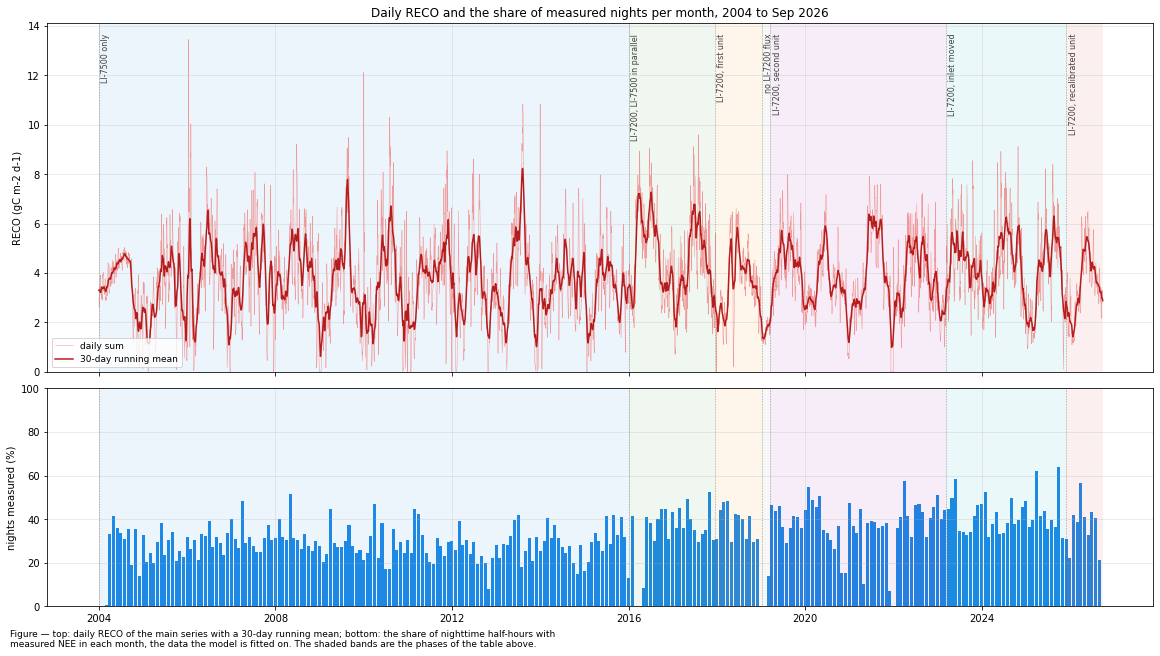

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(16, 9), dpi=72, sharex=True, layout="constrained",
                        height_ratios=[1.6, 1])
_d = df_full[varname].resample('D').sum() * UMOL_TO_GC
axs[0].plot(_d.index, _d, color='#EF9A9A', lw=0.5, label="daily sum")
axs[0].plot(_d.index, _d.rolling(30, center=True, min_periods=15).mean(), color='#B71C1C', lw=1.5,
            label="30-day running mean")
axs[0].set_ylabel(f"RECO ({units_sum} d-1)")
axs[0].set_ylim(bottom=0)
_night = df_full[NIGHTTIME].eq(1)
_m = df_full.loc[_night, nee_flag].eq(0).resample('MS').mean() * 100
axs[1].bar(_m.index, _m, width=25, color='#1E88E5')
axs[1].set_ylabel("nights measured (%)")
axs[1].set_ylim(0, 100)
for _ax in axs:
    shade_phases(_ax)
    _ax.grid(alpha=0.3)
_ymax = axs[0].get_ylim()[1]
for start, name, _, _ in PHASES:
    axs[0].text(pd.Timestamp(start) + pd.Timedelta('20D'), _ymax * 0.97, name, rotation=90,
                va='top', ha='left', fontsize=8, color='#424242')
axs[0].legend(loc='lower left', fontsize=9)
axs[0].set_title(f"Daily RECO and the share of measured nights per month, "
                 f"{df_full.index[0]:%Y} to {df_full.index[-1]:%b %Y}")
figcap(fig, "top: daily RECO of the main series with a 30-day running mean; bottom: the share of "
            "nighttime half-hours with measured NEE in each month, the data the model is fitted on. "
            "The shaded bands are the phases of the table above.")
fig.show()

## 📋 Table: half-hours per analyser and year

In [9]:
_src = df_full[sourcename].groupby(df_full.index.year).value_counts().unstack(fill_value=0)
_src.columns = [SOURCE_LEGEND[c] for c in _src.columns]
_src.index.name = 'YEAR'
display(styled(_src, caption="half-hours per year by the analyser the merged record takes them from",
               fmt="{:.0f}", cmap=None))

Table — half-hours per year by the analyser the merged record takes them from



,"LI-7500 (open path, IRGA75)","LI-7200 (enclosed path, IRGA72)"
YEAR,,
2004,17568,0
2005,17520,0
2006,17520,0
2007,17520,0
2008,17568,0
2009,17520,0
2010,17520,0
2011,17520,0
2012,17568,0


</br>

# Coverage of the nighttime NEE

`RECO` has no gaps, because the model is evaluated at every half-hour. What it rests on is the
measured nighttime `NEE` of each year. Nighttime records are removed more often than daytime ones,
mostly by the USTAR filter on calm nights, and for the open-path LI-7500 also in wet weather. The
shares by temperature show which nights the fit sees.

## 📋 Table: measured nighttime NEE per year

In [10]:
_years = range(FIRST_YEAR, LAST_YEAR + 1)
_ta = df[TA]


def _share(mask):
    """Share of nighttime half-hours within `mask` that have measured NEE, per year, in %."""
    return per_year(is_meas.where(is_night & mask).astype(float), 'mean') * 100


coverage = pd.DataFrame({
    'analyser': [era(y) for y in _years],
    'nights measured (%)': _share(pd.Series(True, index=df.index)),
    'nights below 0 °C (%)': _share(_ta < 0),
    'nights 0-10 °C (%)': _share(in_range(_ta, 0, 10)),
    'nights above 10 °C (%)': _share(_ta >= 10),
    'measured nighttime half-hours': per_year(night_meas, 'sum'),
    'records in the fit': per_year(df[nee_fit].notna(), 'sum'),
}, index=_years)
_none = daily['measured night (n)'].eq(0)
coverage['longest run without a measured night (d)'] = [longest_spell(_none.loc[str(y)])[0] for y in _years]
coverage.index.name = 'YEAR'
_pct = ['nights measured (%)', 'nights below 0 °C (%)', 'nights 0-10 °C (%)', 'nights above 10 °C (%)']
display(styled(coverage, caption="share of nighttime half-hours with measured NEE per year, in all nights "
                                 "and by air temperature, the number of measured nighttime half-hours and "
                                 "of the records the fit used (its own night definition), and the longest "
                                 "run of days without a single measured nighttime half-hour",
               fmt={**{c: "{:.1f}" for c in _pct}, 'measured nighttime half-hours': "{:,.0f}",
                    'records in the fit': "{:,.0f}", 'longest run without a measured night (d)': "{:.0f}"},
               subset=_pct, cmap='Blues'))

Table — share of nighttime half-hours with measured NEE per year, in all nights and by air
temperature, the number of measured nighttime half-hours and of the records the fit used (its own
night definition), and the longest run of days without a single measured nighttime half-hour



,analyser,nights measured (%),nights below 0 °C (%),nights 0-10 °C (%),nights above 10 °C (%),measured nighttime half-hours,records in the fit,longest run without a measured night (d)
YEAR,,,,,,,,
2004,LI-7500,21.2,18.0,25.2,24.8,"1,874","1,879",90
2005,LI-7500,26.4,24.1,26.0,28.6,"2,323","2,353",4
2006,LI-7500,29.8,34.3,25.0,31.5,"2,617","2,529",4
2007,LI-7500,32.3,26.8,33.8,32.0,"2,835","2,732",3
2008,LI-7500,32.1,29.5,31.5,34.2,"2,835","2,713",4
2009,LI-7500,28.4,26.4,27.0,30.5,"2,493","2,420",3
2010,LI-7500,27.6,23.9,28.6,29.7,"2,425","2,359",9
2011,LI-7500,29.4,30.7,28.6,30.0,"2,584","2,537",15
2012,LI-7500,24.6,23.4,23.0,29.0,"2,166","2,125",21


## 📊 Plot: measured nights per year and month

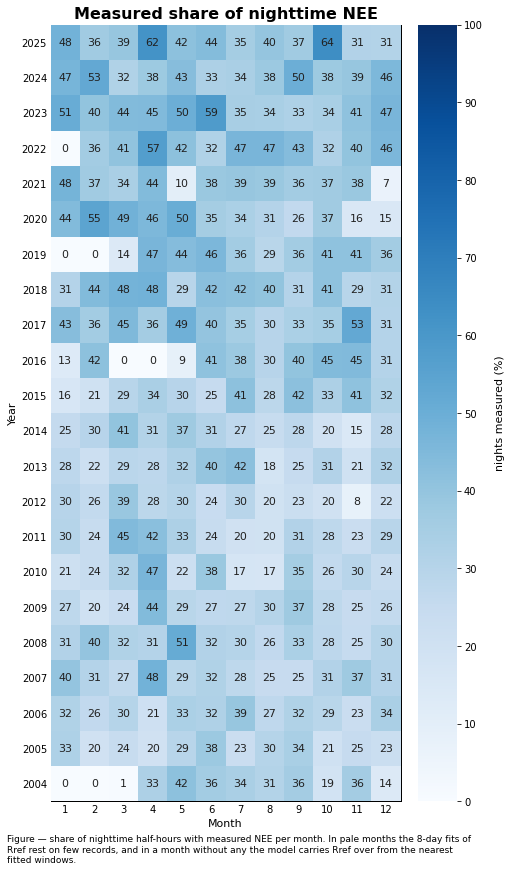

In [11]:
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
_meas_pct = (is_meas.astype(float) * 100).where(is_night).rename("nights measured (%)")
dv.plotting.HeatmapYearMonth(series=_meas_pct, agg='mean').plot(
    ax=ax, cmap="Blues", vmin=0, vmax=100, zlabel="nights measured (%)", show_values=True, cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title="Measured share of nighttime NEE", axlabel_fontsize=11,
                                         ticks_fontsize=10))
figcap(fig, "share of nighttime half-hours with measured NEE per month. In pale months the 8-day fits "
            "of Rref rest on few records, and in a month without any the model carries Rref over from "
            "the nearest fitted windows.")

## 📊 Plot: measured nights by air temperature, per analyser

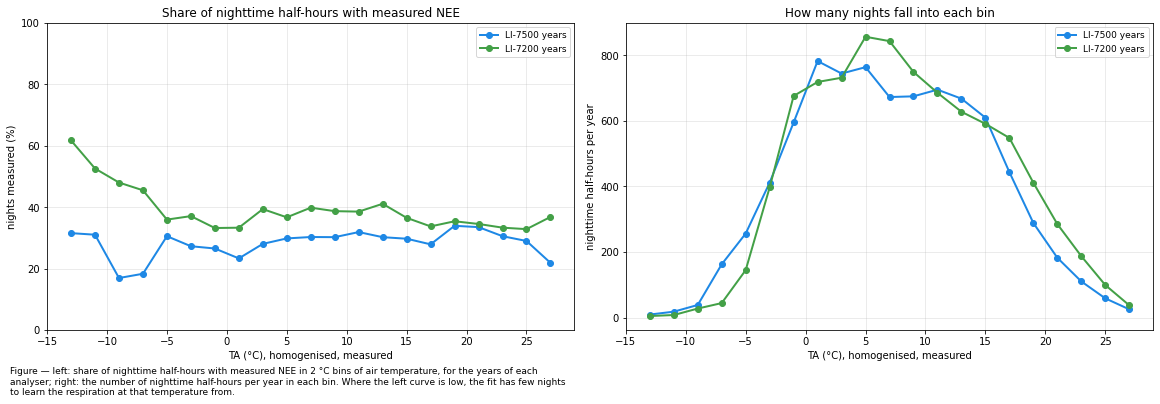

In [12]:
_bins = np.arange(-14, 29, TA_BIN_WIDTH)
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), dpi=72, layout="constrained")
for _name, _sel in ERAS:
    _m = is_night & _sel(df.index)
    _g = is_meas[_m].groupby(pd.cut(_ta[_m], _bins), observed=True)
    _x = [i.mid for i in _g.mean().index]
    axs[0].plot(_x, _g.mean() * 100, marker='o', color=ERA_COLORS[_name], lw=2,
                label=f"{_name} years")
    _n_years = len(set(df.index[_m].year))
    axs[1].plot(_x, _g.size() / _n_years, marker='o', color=ERA_COLORS[_name], lw=2,
                label=f"{_name} years")
axs[0].set_ylabel("nights measured (%)")
axs[0].set_ylim(0, 100)
axs[0].set_title("Share of nighttime half-hours with measured NEE")
axs[1].set_ylabel("nighttime half-hours per year")
axs[1].set_title("How many nights fall into each bin")
for _ax in axs:
    _ax.set_xlabel("TA (°C), homogenised, measured")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
figcap(fig, f"left: share of nighttime half-hours with measured NEE in {TA_BIN_WIDTH} °C bins of air "
            f"temperature, for the years of each analyser; right: the number of nighttime half-hours "
            f"per year in each bin. Where the left curve is low, the fit has few nights to learn the "
            f"respiration at that temperature from.")
fig.show()

</br>

# Annual sums

## 📋 Table: annual sums and their spread

In [13]:
yt = per_year(series, to_gc)
_scen = pd.DataFrame({k: per_year(df[c], to_gc) for k, c in SCENARIOS.items()})
_gpp = per_year(df[gppname], to_gc)
annual = pd.DataFrame({
    'analyser': [era(y) for y in yt.index],
    f"RECO ({units_sum})": yt,
    "USTAR unc.": (_scen['CUT_84'] - _scen['CUT_16']).abs() / 2,
    "CUT_16": _scen['CUT_16'],
    "CUT_84": _scen['CUT_84'],
    "ROB": per_year(df[varname_rob], to_gc),
    "DT": per_year(df[varname_dt], to_gc).where(lambda s: s.index.isin(DT_YEARS)),
    "GPP (NT)": _gpp,
    "RECO / GPP": yt / _gpp,
    "nights measured (%)": coverage['nights measured (%)'],
})
annual["ROB minus NT"] = annual["ROB"] - annual[f"RECO ({units_sum})"]
annual["DT minus NT"] = annual["DT"] - annual[f"RECO ({units_sum})"]
annual["rank (highest first)"] = annual[f"RECO ({units_sum})"].rank(ascending=False).astype(int)
annual.index.name = 'YEAR'
_fmt = {c: "{:.0f}" for c in annual.columns}
_fmt.update({"RECO / GPP": "{:.2f}", "nights measured (%)": "{:.1f}", "ROB minus NT": "{:+.0f}",
             "DT minus NT": "{:+.0f}"})
display(styled(annual, caption=f"annual sums in {units_sum}: RECO of the main series (nighttime method, CUT_50) "
                               f"with its USTAR uncertainty at 1 sigma and the sums of the other two USTAR "
                               f"scenarios; RECO with the outlier-robust Rref (ROB) and from the daytime "
                               f"method (DT), each with its difference to the main series; GPP of the "
                               f"nighttime method and the ratio RECO / GPP; and the share of measured nights",
               fmt=_fmt, subset=[f"RECO ({units_sum})"], cmap='Reds'))

Table — annual sums in gC m-2: RECO of the main series (nighttime method, CUT_50) with its USTAR
uncertainty at 1 sigma and the sums of the other two USTAR scenarios; RECO with the outlier-robust
Rref (ROB) and from the daytime method (DT), each with its difference to the main series; GPP of the
nighttime method and the ratio RECO / GPP; and the share of measured nights



,analyser,RECO (gC m-2),USTAR unc.,CUT_16,CUT_84,ROB,DT,GPP (NT),RECO / GPP,nights measured (%),ROB minus NT,DT minus NT,rank (highest first)
YEAR,,,,,,,,,,,,,
2004,LI-7500,1310,13,1295,1321,1245,-,1270,1.03,21.2,-65,-,16
2005,LI-7500,1157,75,1066,1217,1071,1634,1094,1.06,26.4,-85,+477,22
2006,LI-7500,1407,101,1308,1509,1393,1441,1364,1.03,29.8,-14,+34,10
2007,LI-7500,1453,74,1362,1511,1392,1507,1633,0.89,32.3,-60,+54,7
2008,LI-7500,1501,70,1422,1562,1393,1489,1559,0.96,32.1,-108,-13,4
2009,LI-7500,1261,75,1189,1339,1208,1556,1318,0.96,28.4,-53,+295,19
2010,LI-7500,1274,78,1207,1363,1233,1308,1443,0.88,27.6,-42,+34,18
2011,LI-7500,1409,105,1297,1507,1347,1273,1721,0.82,29.4,-62,-136,9
2012,LI-7500,1222,76,1139,1291,1127,1154,1560,0.78,24.6,-95,-69,20


## 📊 Plot: annual sums with their spread

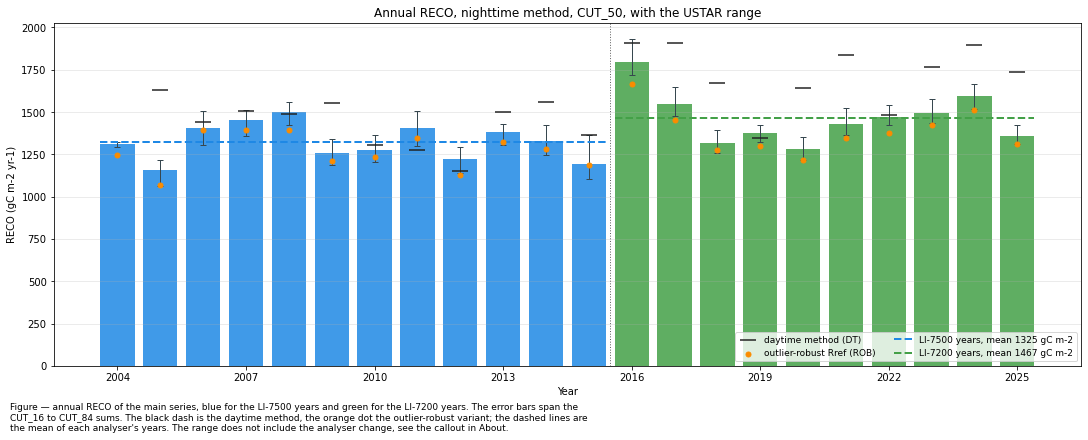

In [14]:
_colors = annual['analyser'].map(ERA_COLORS)
_y = annual[f"RECO ({units_sum})"]
_lo = (_y - annual[['CUT_16', 'CUT_84']].min(axis=1)).clip(lower=0)
_hi = (annual[['CUT_16', 'CUT_84']].max(axis=1) - _y).clip(lower=0)
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.bar(annual.index, _y, color=_colors, alpha=0.85, yerr=[_lo, _hi], capsize=3,
       error_kw=dict(lw=1, ecolor='#37474F'))
ax.scatter(annual.index, annual["DT"], marker='_', s=250, color='#212121', zorder=5,
           label="daytime method (DT)")
ax.scatter(annual.index, annual["ROB"], marker='o', s=25, color='#FB8C00', zorder=6,
           label="outlier-robust Rref (ROB)")
for _name, _c in ERA_COLORS.items():
    _x = annual.loc[annual['analyser'] == _name, f"RECO ({units_sum})"]
    ax.hlines(_x.mean(), _x.index.min() - 0.4, _x.index.max() + 0.4, color=_c, lw=2, ls='--',
              label=f"{_name} years, mean {_x.mean():.0f} {units_sum}")
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_xlabel("Year")
ax.set_ylabel(f"RECO ({units_sum} yr-1)")
ax.set_title("Annual RECO, nighttime method, CUT_50, with the USTAR range")
ax.grid(alpha=0.3, axis='y')
ax.legend(fontsize=9, loc='lower right', ncol=2)
year_axis(ax)
figcap(fig, "annual RECO of the main series, blue for the LI-7500 years and green for the LI-7200 years. "
            "The error bars span the CUT_16 to CUT_84 sums. The black dash is the daytime method, the "
            "orange dot the outlier-robust variant; the dashed lines are the mean of each analyser's "
            "years. The range does not include the analyser change, see the callout in About.")
fig.show()

## 📋 Table: the LI-7500 years against the LI-7200 years

In [15]:
# The two analysers' years side by side. A difference here mixes the forest, the weather and the
# instrument; the temperature response and the parallel period further below separate them.
_cols = [f"RECO ({units_sum})", "ROB", "DT", "GPP (NT)", "RECO / GPP", "nights measured (%)"]
_g = annual.groupby('analyser')[_cols]
eras = pd.concat({'mean': _g.mean(), 'SD between years': _g.std(), 'years': _g.count()}, axis=1)
eras = eras.loc[['LI-7500', 'LI-7200']]
eras.loc['difference (LI-7200 minus LI-7500)', 'mean'] = (eras.loc['LI-7200', 'mean']
                                                          - eras.loc['LI-7500', 'mean']).to_numpy()
_fmt = {c: ("{:.0f}" if c[0] == 'years' else "{:.2f}" if c[1] == "RECO / GPP"
            else "{:.1f}" if c[1] == "nights measured (%)" else "{:.0f}") for c in eras.columns}
display(styled(eras, caption=f"means of the annual sums over the years of each analyser, {FIRST_YEAR}-2015 "
                             f"and 2016-{LAST_YEAR}, with the standard deviation between years. RECO (DT) "
                             f"of the LI-7500 years starts in {DT_YEARS[0]}",
               fmt=_fmt, cmap=None))

Table — means of the annual sums over the years of each analyser, 2004-2015 and 2016-2025, with the
standard deviation between years. RECO (DT) of the LI-7500 years starts in 2005



</br>

# RECO and GPP

The nighttime method derives `GPP` as `RECO − NEE`. An error of `RECO` therefore enters `GPP` in
full, and the ratio of the two says how much of the gross uptake the model returns as respiration.
A ratio below 1 is a net sink.

## 📊 Plot: annual RECO and GPP, and their ratio

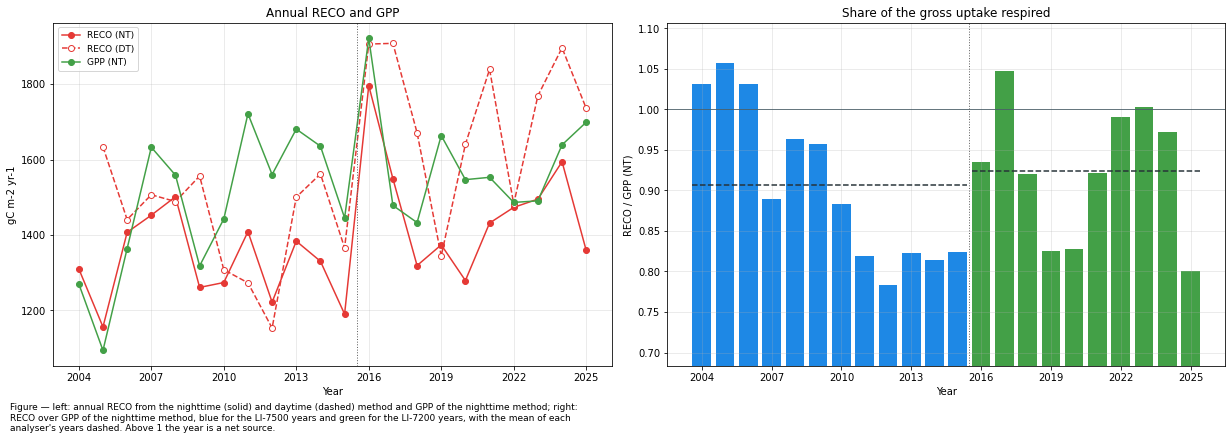

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6), dpi=72, layout="constrained")
axs[0].plot(annual.index, annual[f"RECO ({units_sum})"], color='#E53935', marker='o', label="RECO (NT)")
axs[0].plot(annual.index, annual["DT"], color='#E53935', ls='--', marker='o', mfc='white', label="RECO (DT)")
axs[0].plot(annual.index, annual["GPP (NT)"], color='#43A047', marker='o', label="GPP (NT)")
axs[0].set_ylabel(f"{units_sum} yr-1")
axs[0].set_title("Annual RECO and GPP")
axs[0].legend(fontsize=9)
axs[1].bar(annual.index, annual["RECO / GPP"], color=annual['analyser'].map(ERA_COLORS))
axs[1].axhline(1, color='#455A64', lw=0.8)
_r = annual["RECO / GPP"]
axs[1].set_ylim(max(0, _r.min() - 0.1), _r.max() + 0.05)
for _name, _c in ERA_COLORS.items():
    _x = _r[annual['analyser'] == _name]
    axs[1].hlines(_x.mean(), _x.index.min() - 0.4, _x.index.max() + 0.4, color='#263238', lw=1.5,
                  ls='--')
axs[1].set_ylabel("RECO / GPP (NT)")
axs[1].set_title("Share of the gross uptake respired")
for _ax in axs:
    _ax.axvline(2015.5, color='#616161', lw=1, ls=':')
    _ax.grid(alpha=0.3)
    _ax.set_xlabel("Year")
    year_axis(_ax)
figcap(fig, "left: annual RECO from the nighttime (solid) and daytime (dashed) method and GPP of the "
            "nighttime method; right: RECO over GPP of the nighttime method, blue for the LI-7500 years and "
            "green for the LI-7200 years, with the mean of each analyser's years dashed. Above 1 the year "
            "is a net source.")
fig.show()

</br>

# Seasonality

## Monthly sums per year

### 📋 Table: monthly sums per year

In [17]:
monthly_sum = per_year_month(series, to_gc)
monthly_by_number = per_year_month(series, to_gc, month_names=False)
display(styled(monthly_sum, caption=f"monthly RECO sums ({units_sum}), one row per year; the colour scale runs "
                                    f"over the whole table",
               fmt="{:.0f}", cmap='Reds', axis=None))

Table — monthly RECO sums (gC m-2), one row per year; the colour scale runs over the whole table



,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
YEAR,,,,,,,,,,,,
2004,100,99,111,120,130,135,142,144,134,82,60,54
2005,79,32,82,69,113,138,126,139,123,116,82,58
2006,157,78,56,112,138,186,164,126,140,125,84,42
2007,102,88,81,132,139,148,172,120,164,99,121,85
2008,113,101,91,115,176,167,145,123,143,133,116,78
2009,34,52,75,108,139,129,134,236,117,103,86,49
2010,83,67,40,101,114,147,138,204,147,92,67,72
2011,55,58,87,139,128,116,114,131,131,152,161,136
2012,108,60,81,61,143,154,124,164,95,60,72,100


## Climatology per calendar month

### 📋 Table: climatology per calendar month

In [18]:
_by_month = monthly_by_number
climatology = pd.DataFrame({
    f"mean ({units_sum})": _by_month.mean(),
    "SD between years": _by_month.std(),
    "highest": _by_month.max(),
    "in": _by_month.idxmax(),
    "lowest": _by_month.min(),
    "in ": _by_month.idxmin(),
    "mean, LI-7500 years": _by_month.loc[:2015].mean(),
    "mean, LI-7200 years": _by_month.loc[2016:].mean(),
})
climatology["LI-7200 minus LI-7500"] = climatology["mean, LI-7200 years"] - climatology["mean, LI-7500 years"]
climatology["LI-7200 minus LI-7500 (%)"] = (climatology["LI-7200 minus LI-7500"]
                                            / climatology["mean, LI-7500 years"] * 100)
climatology.index = [calendar.month_abbr[m] for m in climatology.index]
climatology.index.name = 'MONTH'
_fmt = {c: "{:.0f}" for c in climatology.columns}
_fmt["LI-7200 minus LI-7500"] = "{:+.0f}"
_fmt["LI-7200 minus LI-7500 (%)"] = "{:+.0f}"
display(styled(climatology, caption=f"each calendar month across {FIRST_YEAR}-{LAST_YEAR}: its mean sum, the "
                                    f"spread between years, the highest and lowest sum with their years, and "
                                    f"the mean over the years of each analyser. The last two columns show in "
                                    f"which months the two analysers' years differ, in {units_sum} and relative "
                                    f"to the LI-7500 years",
               fmt=_fmt, subset=["LI-7200 minus LI-7500 (%)"], cmap='RdBu_r', center=True))

Table — each calendar month across 2004-2025: its mean sum, the spread between years, the highest
and lowest sum with their years, and the mean over the years of each analyser. The last two columns
show in which months the two analysers' years differ, in gC m-2 and relative to the LI-7500 years



,mean (gC m-2),SD between years,highest,in,lowest,in,"mean, LI-7500 years","mean, LI-7200 years",LI-7200 minus LI-7500,LI-7200 minus LI-7500 (%)
MONTH,,,,,,,,,,
Jan,84,26,157,2006,34,2009,91,75,-16,-18
Feb,71,18,101,2008,32,2005,67,75,+7,+11
Mar,84,35,214,2016,40,2010,75,96,+22,+29
Apr,113,27,194,2016,61,2012,105,122,+17,+17
May,140,19,176,2008,105,2018,138,142,+4,+3
Jun,156,26,195,2017,101,2014,142,174,+32,+23
Jul,150,24,202,2016,114,2011,144,158,+14,+10
Aug,157,36,236,2009,102,2020,156,159,+3,+2
Sep,137,20,184,2021,95,2012,130,144,+14,+11


## Mean annual cycle

### 📊 Plot: mean annual cycle of daily RECO, per analyser

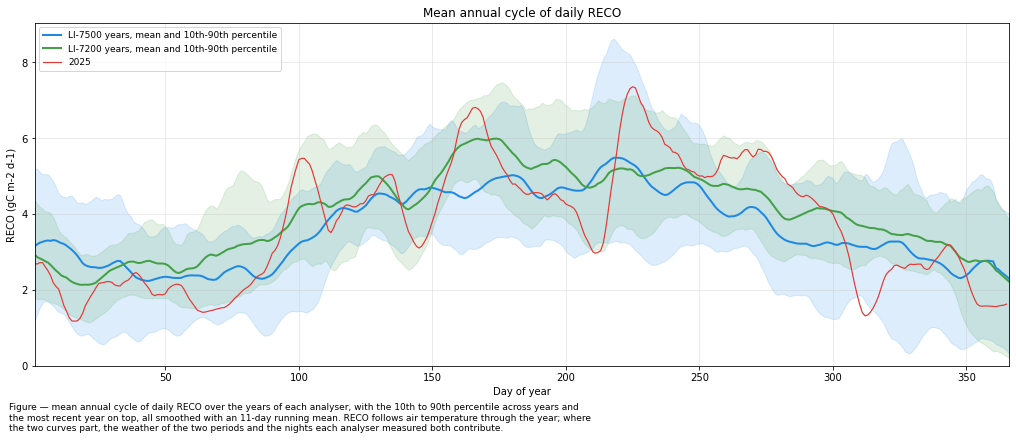

In [19]:
# Daily sums per day of year, smoothed with an 11-day running mean, for the years of each analyser.
fig, ax = plt.subplots(figsize=(14, 6), dpi=72, layout="constrained")
_sm = lambda s: s.rolling(11, center=True, min_periods=3).mean()
for _name, _sel in (('LI-7500', daily.loc[:'2015']), ('LI-7200', daily.loc['2016':])):
    _g = _sel['RECO'].groupby(_sel.index.dayofyear)
    _c = ERA_COLORS[_name]
    ax.fill_between(_g.mean().index, _sm(_g.quantile(0.1)), _sm(_g.quantile(0.9)), color=_c, alpha=0.15)
    ax.plot(_g.mean().index, _sm(_g.mean()), color=_c, lw=2,
            label=f"{_name} years, mean and 10th-90th percentile")
_last = daily.loc[str(LAST_YEAR), 'RECO']
ax.plot(_last.index.dayofyear, _sm(_last), color='#E53935', lw=1.2, label=str(LAST_YEAR))
ax.set_xlim(1, 366)
ax.set_ylim(bottom=0)
ax.set_xlabel("Day of year")
ax.set_ylabel(f"RECO ({units_sum} d-1)")
ax.set_title("Mean annual cycle of daily RECO")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='upper left')
figcap(fig, "mean annual cycle of daily RECO over the years of each analyser, with the 10th to 90th "
            "percentile across years and the most recent year on top, all smoothed with an 11-day running "
            "mean. RECO follows air temperature through the year; where the two curves part, the weather "
            "of the two periods and the nights each analyser measured both contribute.")
fig.show()

## Mean diurnal cycle per month

### 📊 Plot: mean diurnal cycle per month, per analyser

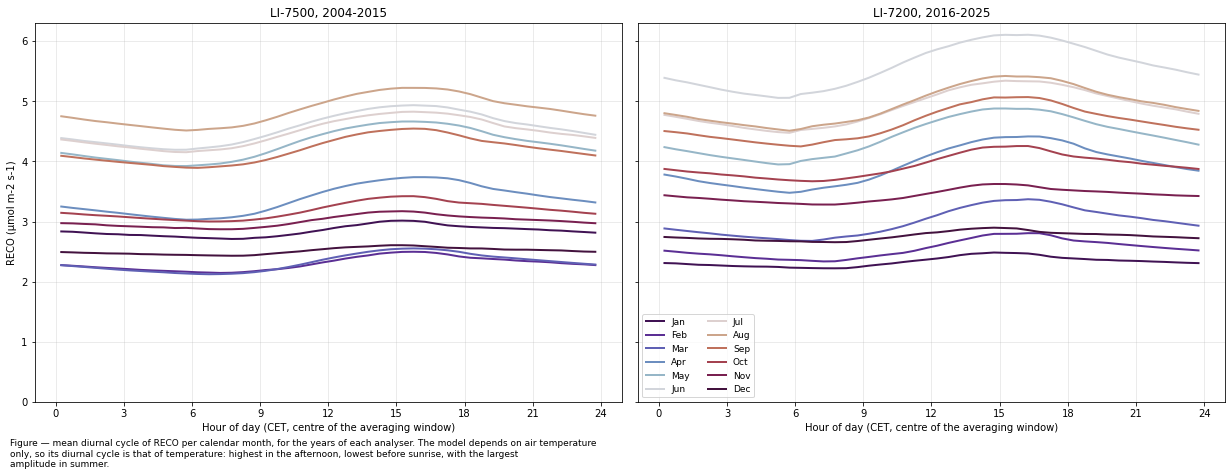

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, sharey=True, layout="constrained")
_colors = plt.get_cmap('twilight_shifted')(np.linspace(0.05, 0.95, 12))
for _ax, (_name, _s) in zip(axs, (('LI-7500, 2004-2015', series.loc[:'2015']),
                                  (f'LI-7200, 2016-{LAST_YEAR}', series.loc['2016':]))):
    _diurnal = _s.groupby([_s.index.month, _s.index.hour + _s.index.minute / 60]).mean().unstack(0)
    for _i, _month in enumerate(_diurnal.columns):
        _ax.plot(_diurnal.index, _diurnal[_month], color=_colors[_i], lw=2, label=calendar.month_abbr[_month])
    _ax.set_xticks(range(0, 25, 3))
    _ax.set_xlabel("Hour of day (CET, centre of the averaging window)")
    _ax.set_title(_name)
    _ax.grid(alpha=0.3)
axs[0].set_ylabel(xlabel)
axs[0].set_ylim(bottom=0)
axs[1].legend(ncol=2, fontsize=9)
figcap(fig, "mean diurnal cycle of RECO per calendar month, for the years of each analyser. The model "
            "depends on air temperature only, so its diurnal cycle is that of temperature: highest in the "
            "afternoon, lowest before sunrise, with the largest amplitude in summer.")
fig.show()

## Month by hour

### 📊 Plot: month by hour, and the difference between the analysers' years

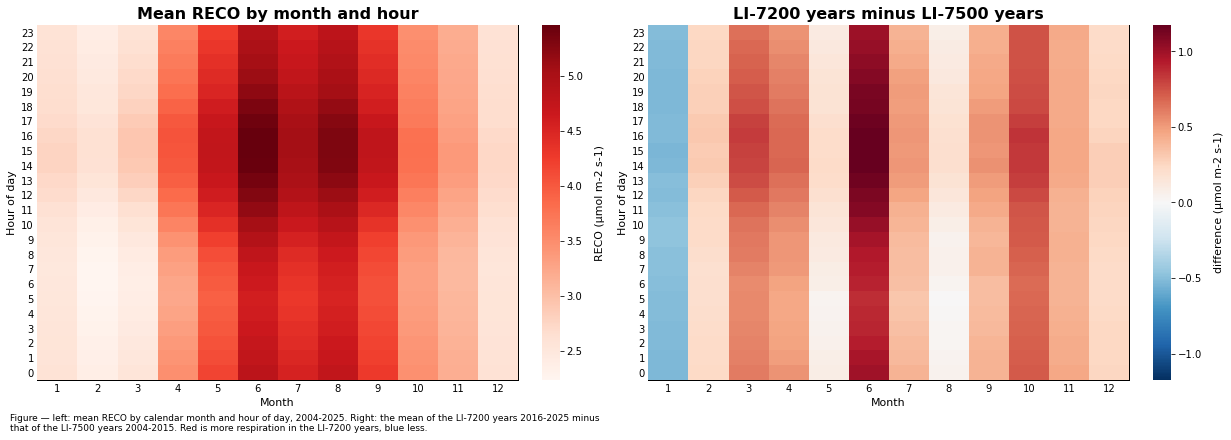

In [21]:
def _by_month_hour(s):
    """Mean of `s` per calendar month and hour, in the long form HeatmapXYZ expects."""
    frame = pd.DataFrame({'MONTH': s.index.month, 'HOUR': s.index.hour, 'z': s.to_numpy()})
    return frame.groupby(['MONTH', 'HOUR'], as_index=False)['z'].mean()


_all = _by_month_hour(series)
_diff = _by_month_hour(series.loc['2016':])
_diff['z'] = _diff['z'].to_numpy() - _by_month_hour(series.loc[:'2015'])['z'].to_numpy()
_absmax = _diff['z'].abs().max()
_style = dict(axlabel_fontsize=11, ticks_fontsize=10)
fig, axs = plt.subplots(ncols=2, figsize=(17, 6), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_all['MONTH'], y=_all['HOUR'], z=_all['z']).plot(
    ax=axs[0], cmap='Reds', xlabel="Month", ylabel="Hour of day", zlabel=xlabel, cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title=f"Mean {var} by month and hour", **_style))
dv.plotting.HeatmapXYZ(x=_diff['MONTH'], y=_diff['HOUR'], z=_diff['z']).plot(
    ax=axs[1], cmap='RdBu_r', vmin=-_absmax, vmax=_absmax, xlabel="Month", ylabel="Hour of day",
    zlabel=f"difference ({units})", cb_labelsize=10,
    format_style=dv.plotting.FormatStyle(title="LI-7200 years minus LI-7500 years", **_style))
figcap(fig, f"left: mean RECO by calendar month and hour of day, {FIRST_YEAR}-{LAST_YEAR}. Right: the mean "
            f"of the LI-7200 years 2016-{LAST_YEAR} minus that of the LI-7500 years 2004-2015. Red is "
            f"more respiration in the LI-7200 years, blue less.")

</br>

# Extremes

From the modelled series, with the air temperature, the reference respiration `Rref` and the number of
measured nighttime half-hours of each day listed beside it. `RECO` is high on a warm day or where the
8-day fit found a high `Rref`, which happens in windows with few and scattered nighttime records. It
is very low on a very cold day or where the fit of `Rref` reached its lower bound.

## The days of highest and lowest RECO

### 📋 Table: the days of highest RECO

In [22]:
def _ranked_days(_label, _ranked):
    _table = pd.DataFrame({"date": [f"{_d:%d %b %Y}" for _d in _ranked.index],
                           f"RECO ({units_sum} d-1)": _ranked.to_numpy(),
                           f"RECO DT ({units_sum} d-1)": daily.loc[_ranked.index, 'RECO_DT'].to_numpy(),
                           f"GPP NT ({units_sum} d-1)": daily.loc[_ranked.index, 'GPP_NT'].to_numpy(),
                           "TA (°C)": daily.loc[_ranked.index, 'TA (°C)'].to_numpy(),
                           f"Rref ({units})": daily.loc[_ranked.index, 'Rref'].to_numpy(),
                           "measured nighttime half-hours": daily.loc[_ranked.index, 'measured night (n)'].to_numpy(),
                           "analyser": [era(_d.year) for _d in _ranked.index]},
                          index=range(1, N_EXTREMES + 1))
    _table.index.name = "rank"
    display(styled(_table, caption=f"the {N_EXTREMES} days of {_label} in {FIRST_YEAR}-{LAST_YEAR}, with "
                                   f"daytime RECO, GPP, the mean measured air temperature, the median Rref "
                                   f"and the measured nighttime half-hours of the day",
                   fmt={f"RECO ({units_sum} d-1)": "{:.2f}", f"RECO DT ({units_sum} d-1)": "{:.2f}",
                        f"GPP NT ({units_sum} d-1)": "{:.2f}", "TA (°C)": "{:.1f}",
                        f"Rref ({units})": "{:.2g}",
                        "measured nighttime half-hours": "{:.0f}"},
                   subset=["TA (°C)"], cmap='RdYlBu_r'))


_ranked_days('highest RECO', daily['RECO'].nlargest(N_EXTREMES))

Table — the 10 days of highest RECO in 2004-2025, with daytime RECO, GPP, the mean measured air
temperature, the median Rref and the measured nighttime half-hours of the day



,date,RECO (gC m-2 d-1),RECO DT (gC m-2 d-1),GPP NT (gC m-2 d-1),TA (°C),Rref (µmol m-2 s-1),measured nighttime half-hours,analyser
rank,,,,,,,,
1,12 Jan 2006,13.46,1.28,6.04,-2.5,28,8,LI-7500
2,01 Jan 2010,12.11,8.98,11.37,2.2,26,0,LI-7500
3,13 Jan 2006,11.81,0.92,8.20,-5.7,30,0,LI-7500
4,31 Dec 2013,10.84,1.85,6.67,1.0,16,4,LI-7500
5,10 Aug 2013,10.83,11.02,15.98,16.9,10,0,LI-7500
6,09 Aug 2013,10.83,4.47,10.29,15.3,10,5,LI-7500
7,11 Aug 2013,10.52,13.88,15.16,17.7,9.6,0,LI-7500
8,12 Aug 2013,10.32,13.95,14.49,19.2,9.1,0,LI-7500
9,04 Aug 2010,10.31,8.85,15.98,16.3,9.3,3,LI-7500


### 📋 Table: the days of lowest RECO

In [23]:
_ranked_days('lowest RECO', daily['RECO'].nsmallest(N_EXTREMES))

Table — the 10 days of lowest RECO in 2004-2025, with daytime RECO, GPP, the mean measured air
temperature, the median Rref and the measured nighttime half-hours of the day



,date,RECO (gC m-2 d-1),RECO DT (gC m-2 d-1),GPP NT (gC m-2 d-1),TA (°C),Rref (µmol m-2 s-1),measured nighttime half-hours,analyser
rank,,,,,,,,
1,07 Feb 2012,0.00,0.75,-1.87,-13.6,1e-06,10,LI-7500
2,06 Feb 2012,0.00,0.83,-1.92,-13.4,1e-06,14,LI-7500
3,05 Feb 2012,0.00,0.94,-1.39,-13.2,1e-06,10,LI-7500
4,04 Feb 2012,0.00,1.04,-1.13,-12.9,1e-06,23,LI-7500
5,03 Feb 2012,0.00,0.99,-2.31,-12.7,1e-06,11,LI-7500
6,29 Dec 2017,0.00,4.42,2.90,-2.1,1e-06,9,LI-7200
7,08 Jan 2009,0.00,3.39,-1.07,-7.8,1e-06,7,LI-7500
8,10 Jan 2009,0.00,3.25,-1.07,-7.5,1e-06,0,LI-7500
9,04 Jan 2009,0.00,2.96,-0.99,-7.4,1e-06,9,LI-7500


## 📋 Table: periods of near-zero RECO

In [24]:
# The fit of Rref in an 8-day window is bounded below. Where the measured nighttime NEE of a window
# is near zero or negative, Rref sits at that bound and RECO is practically zero whatever the
# temperature. Such periods are listed here: runs of consecutive days with half-hours below
# RECO_NEAR_ZERO, holding at least NEAR_ZERO_MIN_RECORDS of them.
_low = series.lt(RECO_NEAR_ZERO)
_d = _low.resample('D').sum()
_d = _d[_d > 0]
_blocks = (_d.index.to_series().diff() != pd.Timedelta('1D')).cumsum()
_rows = []
for _, _g in _d.groupby(_blocks):
    if _g.sum() < NEAR_ZERO_MIN_RECORDS:
        continue
    _s, _e = _g.index[0], _g.index[-1]
    _sel = df.loc[f"{_s:%Y-%m-%d}":f"{_e:%Y-%m-%d}"]
    _night = _sel.loc[_sel[NIGHTTIME].eq(1), nee_measured]
    _rows.append({'from': f"{_s:%d %b %Y}", 'to': f"{_e:%d %b %Y}", 'days': len(_g),
                  'half-hours near zero': int(_g.sum()), 'analyser': era(_s.year),
                  'lowest Rref': _sel[rrefname].min(),
                  'TA (°C)': _sel[TA].mean(),
                  'measured nighttime half-hours': int(_night.notna().sum()),
                  f"median measured nighttime NEE ({units})": _night.median()})
near_zero = pd.DataFrame(_rows)
near_zero.index = range(1, len(near_zero) + 1)
near_zero.index.name = 'period'
display(styled(near_zero, caption=f"periods in which RECO falls below {RECO_NEAR_ZERO} {units} for at least "
                                  f"{NEAR_ZERO_MIN_RECORDS} half-hours, with the lowest Rref, the mean air "
                                  f"temperature, and the number and median of the measured nighttime NEE "
                                  f"records in the period. A median near or below zero is the reason the "
                                  f"fit set Rref to its lower bound",
               fmt={'days': "{:.0f}", 'half-hours near zero': "{:.0f}", 'lowest Rref': "{:.1e}",
                    'TA (°C)': "{:.1f}", 'measured nighttime half-hours': "{:.0f}",
                    f"median measured nighttime NEE ({units})": "{:+.2f}"},
               subset=[f"median measured nighttime NEE ({units})"], cmap='RdBu_r', center=True))
_per_era = near_zero.groupby('analyser')['half-hours near zero'].agg(['count', 'sum'])
for _name in ('LI-7500', 'LI-7200'):
    _n = _per_era.loc[_name] if _name in _per_era.index else pd.Series({'count': 0, 'sum': 0})
    print(f"{_name} years: {int(_n['count'])} periods, {int(_n['sum'])} half-hours near zero")

Table — periods in which RECO falls below 0.1 µmol m-2 s-1 for at least 24 half-hours, with the
lowest Rref, the mean air temperature, and the number and median of the measured nighttime NEE
records in the period. A median near or below zero is the reason the fit set Rref to its lower bound



,from,to,days,half-hours near zero,analyser,lowest Rref,TA (°C),measured nighttime half-hours,median measured nighttime NEE (µmol m-2 s-1)
period,,,,,,,,,
1,29 Nov 2004,30 Nov 2004,2,34,LI-7500,9.5e-07,3.0,22,-0.73
2,31 Dec 2004,31 Dec 2004,1,27,LI-7500,1.0e-06,-1.2,7,+1.89
3,10 Feb 2005,17 Feb 2005,8,308,LI-7500,9.5e-07,-0.4,42,+1.24
4,05 Oct 2005,05 Oct 2005,1,30,LI-7500,9.5e-07,10.1,8,-3.69
5,24 Feb 2006,26 Feb 2006,3,58,LI-7500,9.5e-07,-2.2,31,+0.23
6,20 Dec 2006,25 Dec 2006,6,245,LI-7500,1.0e-06,-1.8,103,+0.01
7,15 Dec 2007,19 Dec 2007,5,183,LI-7500,9.5e-07,-4.6,119,-0.17
8,29 Dec 2008,14 Jan 2009,17,772,LI-7500,1.0e-06,-5.0,87,-0.28
9,27 Jan 2010,28 Jan 2010,2,60,LI-7500,9.5e-07,-5.8,23,+0.29


LI-7500 years: 21 periods, 3372 half-hours near zero
LI-7200 years: 3 periods, 1164 half-hours near zero


</br>

# Temperature response

`RECO` is a function of air temperature, fitted to measured nighttime `NEE`. This section shows the
function the model produced for the years of each analyser, and compares it with the nighttime
`NEE` it was fitted on. At night the model should follow the measured `NEE`. Where the LI-7500 reads
cold nights too low, the model of the LI-7500 years follows it; comparing `RECO` of the two periods at
the same temperature shows how far.

## 📊 Plot: RECO against air temperature, per analyser

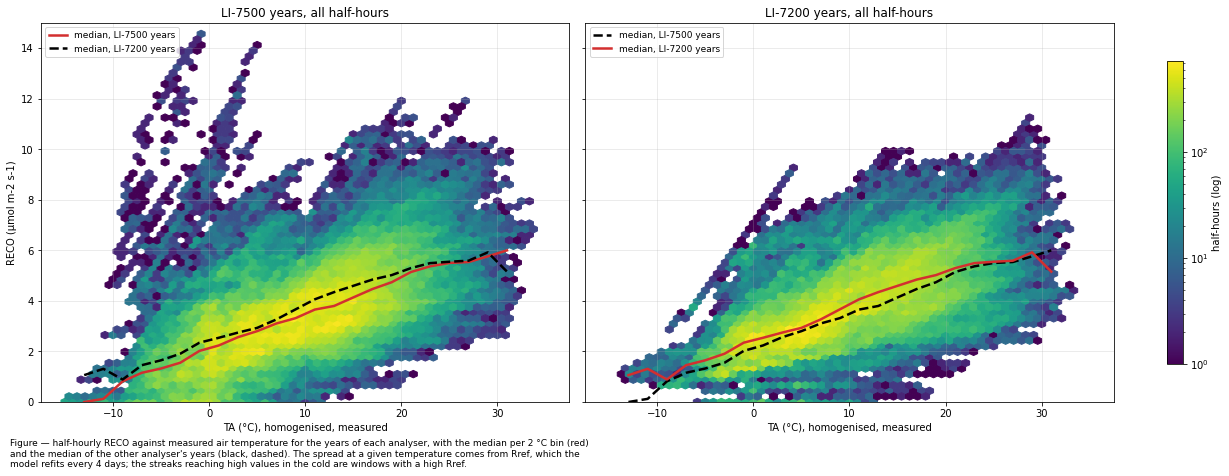

In [25]:
_bins = np.arange(-14, 33, TA_BIN_WIDTH)
_d = df[[varname, TA]].dropna()
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, sharey=True, layout="constrained")
_medians = {}
for _name, _sel in ERAS:
    _s = _d[_sel(_d.index)]
    _medians[_name] = binned_median(_s[TA], _s[varname], _bins)
for _ax, (_name, _sel) in zip(axs, ERAS):
    _s = _d[_sel(_d.index)]
    _hb = _ax.hexbin(_s[TA], _s[varname], gridsize=60, mincnt=1, bins='log', cmap='viridis',
                     extent=(-15, 35, 0, 15))
    for _other, (_x, _m) in _medians.items():
        _ax.plot(_x, _m, color='#D32F2F' if _other == _name else '#000000', lw=2.5,
                 ls='-' if _other == _name else '--', label=f"median, {_other} years")
    _ax.set_title(f"{_name} years, all half-hours")
    _ax.set_xlabel("TA (°C), homogenised, measured")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9, loc='upper left')
axs[0].set_ylabel(xlabel)
axs[0].set_ylim(0, 15)
fig.colorbar(_hb, ax=axs, label="half-hours (log)", shrink=0.8)
figcap(fig, f"half-hourly RECO against measured air temperature for the years of each analyser, with the "
            f"median per {TA_BIN_WIDTH} °C bin (red) and the median of the other analyser's years (black, "
            f"dashed). The spread at a given temperature comes from Rref, which the model refits every "
            f"4 days; the streaks reaching high values in the cold are windows with a high Rref.")
fig.show()

## 📊 Plot: modelled RECO and measured NEE at night, by temperature

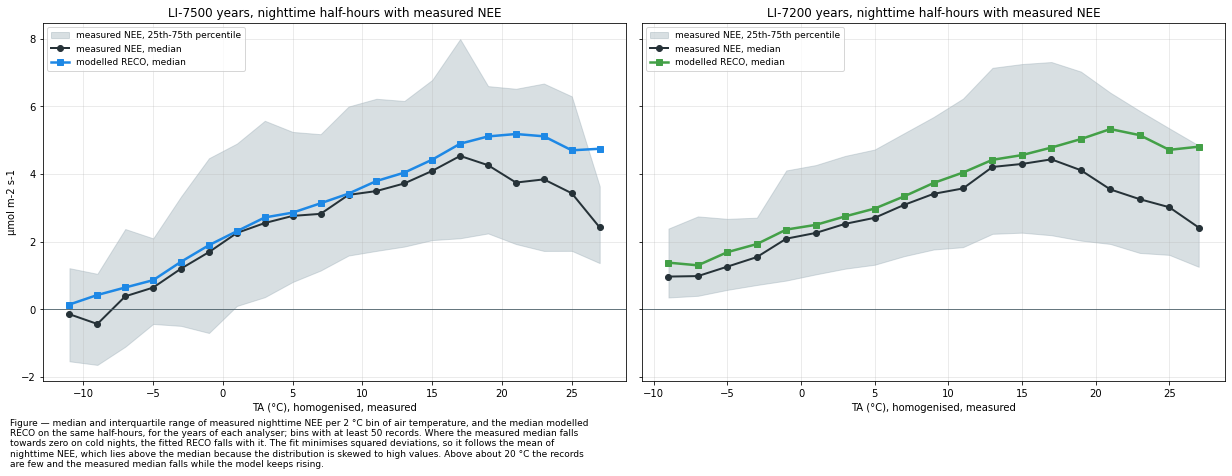

In [26]:
_bins = np.arange(-14, 29, TA_BIN_WIDTH)
_n = df.loc[night_meas, [varname, nee_measured, TA]].dropna()
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), dpi=72, sharey=True, layout="constrained")
for _ax, (_name, _sel) in zip(axs, ERAS):
    _s = _n[_sel(_n.index)]
    _g = _s[nee_measured].groupby(pd.cut(_s[TA], _bins), observed=True)
    _ok = _g.count() >= MIN_RECORDS_BIN
    _x = np.array([i.mid for i in _g.median()[_ok].index])
    _ax.fill_between(_x, _g.quantile(0.25)[_ok], _g.quantile(0.75)[_ok], color='#90A4AE', alpha=0.35,
                     label="measured NEE, 25th-75th percentile")
    _ax.plot(_x, _g.median()[_ok], color='#263238', lw=2, marker='o', label="measured NEE, median")
    _ax.plot(*binned_median(_s[TA], _s[varname], _bins), color=ERA_COLORS[_name], lw=2.5, marker='s',
             label="modelled RECO, median")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_title(f"{_name} years, nighttime half-hours with measured NEE")
    _ax.set_xlabel("TA (°C), homogenised, measured")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9, loc='upper left')
axs[0].set_ylabel(f"{units}")
figcap(fig, f"median and interquartile range of measured nighttime NEE per {TA_BIN_WIDTH} °C bin of air "
            f"temperature, and the median modelled RECO on the same half-hours, for the years of each "
            f"analyser; bins with at least {MIN_RECORDS_BIN} records. Where the measured median falls "
            f"towards zero on cold nights, the fitted RECO falls with it. The fit minimises squared "
            f"deviations, so it follows the mean of nighttime NEE, which lies above the median because "
            f"the distribution is skewed to high values. Above about 20 °C the records are few and the "
            f"measured median falls while the model keeps rising.")
fig.show()

## 📋 Table: RECO against measured nighttime NEE, by temperature class

In [27]:
_n = df.loc[night_meas, [varname, nee_measured, TA]].dropna()
_cls = pd.cut(_n[TA], TA_CLASSES, right=False)
_labels = {iv: (f"below {iv.right:g} °C" if iv.left == TA_CLASSES[0] else
                f"{iv.left:g} °C and above" if iv.right == TA_CLASSES[-1] else
                f"{iv.left:g} to {iv.right:g} °C") for iv in _cls.cat.categories}
_tables = {}
for _name, _sel in ERAS:
    _m = _sel(_n.index)
    _g = _n[_m].groupby(_cls[_m], observed=True)
    _tables[_name] = pd.DataFrame({
        f"{_name}: records": _g.size(),
        f"{_name}: NEE": _g[nee_measured].median(),
        f"{_name}: NEE < 0 (%)": _g[nee_measured].apply(lambda s: (s < 0).mean() * 100),
        f"{_name}: RECO": _g[varname].median(),
        f"{_name}: RECO minus NEE": _g[varname].median() - _g[nee_measured].median(),
    })
by_class = pd.concat(_tables.values(), axis=1)
by_class["RECO, LI-7200 minus LI-7500"] = by_class["LI-7200: RECO"] - by_class["LI-7500: RECO"]
by_class["NEE, LI-7200 minus LI-7500"] = by_class["LI-7200: NEE"] - by_class["LI-7500: NEE"]
by_class.index = [_labels[i] for i in by_class.index]
by_class.index.name = 'TA class'
_fmt = {c: ("{:,.0f}" if 'records' in c else "{:.0f}" if '(%)' in c else "{:+.2f}") for c in by_class.columns}
display(styled(by_class, caption=f"medians of measured nighttime NEE and of modelled RECO on the same half-hours, "
                                 f"in {units}, by class of air temperature for the years of each analyser, with "
                                 f"the share of negative nighttime NEE (apparent uptake in the dark) and the "
                                 f"differences between the two periods",
               fmt=_fmt, subset=["RECO, LI-7200 minus LI-7500", "NEE, LI-7200 minus LI-7500"],
               cmap='RdBu_r', center=True))

Table — medians of measured nighttime NEE and of modelled RECO on the same half-hours, in µmol m-2
s-1, by class of air temperature for the years of each analyser, with the share of negative
nighttime NEE (apparent uptake in the dark) and the differences between the two periods



,LI-7500: records,LI-7500: NEE,LI-7500: NEE < 0 (%),LI-7500: RECO,LI-7500: RECO minus NEE,LI-7200: records,LI-7200: NEE,LI-7200: NEE < 0 (%),LI-7200: RECO,LI-7200: RECO minus NEE,"RECO, LI-7200 minus LI-7500","NEE, LI-7200 minus LI-7500"
TA class,,,,,,,,,,,,
below -5 °C,"1,017",+0.36,43,+0.67,+0.31,589,+1.14,12,+1.49,+0.35,+0.83,+0.79
-5 to 0 °C,"3,745",+1.31,31,+1.54,+0.23,"4,048",+1.74,12,+2.15,+0.41,+0.60,+0.43
0 to 5 °C,"6,139",+2.50,22,+2.62,+0.12,"6,804",+2.45,11,+2.70,+0.25,+0.07,-0.05
5 to 10 °C,"6,170",+3.05,15,+3.20,+0.15,"7,859",+3.12,8,+3.42,+0.30,+0.22,+0.07
10 to 15 °C,"6,203",+3.67,9,+3.96,+0.30,"6,338",+3.95,7,+4.32,+0.36,+0.35,+0.28
15 to 20 °C,"3,706",+4.33,7,+4.87,+0.54,"4,340",+4.32,8,+4.81,+0.49,-0.06,-0.01
20 °C and above,"1,428",+3.61,9,+5.09,+1.49,"2,108",+3.25,8,+5.21,+1.95,+0.11,-0.35


## 📋 Table: model parameters and nighttime fluxes at fixed temperatures, per year

In [28]:
# Per year: the temperature sensitivity E0, the median Rref (RECO at TREF), and the medians of
# nighttime RECO (all nights) and of measured nighttime NEE in the FIXED_TA ranges. Comparing years at
# a fixed temperature removes the weather of the year from the comparison.
_night = df[is_night]
_rows = {}
for _y in range(FIRST_YEAR, LAST_YEAR + 1):
    _s = _night.loc[str(_y)]
    _row = {'analyser': era(_y), 'E0 (K)': _s[e0name].iloc[0], f"median Rref ({units})": df.loc[str(_y), rrefname].median()}
    for _label, (_lo, _hi) in FIXED_TA.items():
        _in = in_range(_s[TA], _lo, _hi)
        _row[f"RECO, {_label}"] = _s.loc[_in, varname].median()
        _row[f"NEE, {_label}"] = _s.loc[_in, nee_measured].median()
    _rows[_y] = _row
fixed = pd.DataFrame.from_dict(_rows, orient='index')
fixed.index.name = 'YEAR'
_flux_cols = [c for c in fixed.columns if c.startswith(('RECO,', 'NEE,'))]
display(styled(fixed, caption=f"per year: the temperature sensitivity E0 of the model, the median reference "
                              f"respiration Rref (RECO at {TREF:g} °C), and the medians of nighttime RECO "
                              f"(all nights) and of measured nighttime NEE (nights with a measurement) in three "
                              f"fixed ranges of air temperature, in {units}",
               fmt={'E0 (K)': "{:.0f}", f"median Rref ({units})": "{:.2f}", **{c: "{:+.2f}" for c in _flux_cols}},
               subset=_flux_cols, cmap='Reds'))

Table — per year: the temperature sensitivity E0 of the model, the median reference respiration Rref
(RECO at 15 °C), and the medians of nighttime RECO (all nights) and of measured nighttime NEE
(nights with a measurement) in three fixed ranges of air temperature, in µmol m-2 s-1



,analyser,E0 (K),median Rref (µmol m-2 s-1),"RECO, below 0 °C","NEE, below 0 °C","RECO, 4-6 °C","NEE, 4-6 °C","RECO, 14-16 °C","NEE, 14-16 °C"
YEAR,,,,,,,,,
2004,LI-7500,57,4.28,+1.68,+2.09,+2.56,+2.59,+2.53,+2.14
2005,LI-7500,116,3.76,+1.46,+1.19,+2.68,+2.13,+3.90,+3.34
2006,LI-7500,117,4.26,+1.42,+1.12,+2.43,+2.80,+4.77,+5.00
2007,LI-7500,113,4.79,+2.49,+0.46,+2.68,+2.43,+5.12,+4.76
2008,LI-7500,107,4.89,+2.53,+0.94,+3.52,+2.94,+5.23,+5.01
2009,LI-7500,135,3.89,+1.00,+1.04,+2.23,+2.22,+3.73,+3.29
2010,LI-7500,185,4.54,+1.14,+1.09,+2.93,+2.45,+4.87,+4.38
2011,LI-7500,104,4.14,+1.26,+0.35,+3.58,+3.53,+4.13,+4.02
2012,LI-7500,103,3.62,+2.51,+0.83,+2.41,+2.70,+3.71,+4.07


## 📊 Plot: the model parameters over time

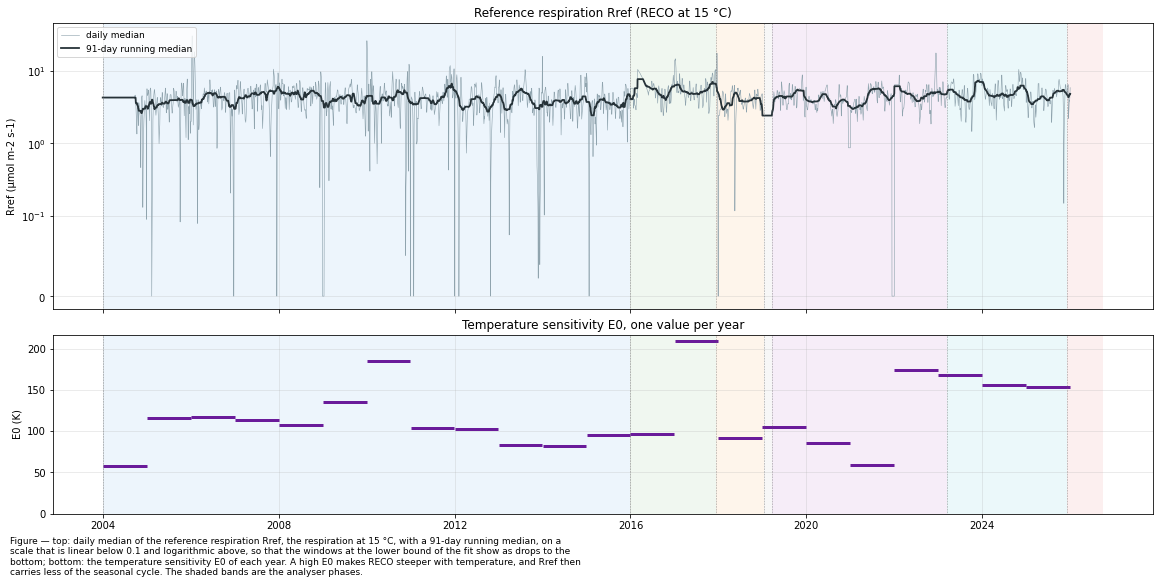

In [29]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), dpi=72, sharex=True, layout="constrained", height_ratios=[1.6, 1])
_r = daily['Rref']
axs[0].plot(_r.index, _r, color='#90A4AE', lw=0.6, label="daily median")
axs[0].plot(_r.index, _r.rolling(91, center=True, min_periods=45).median(), color='#263238', lw=1.8,
            label="91-day running median")
axs[0].set_yscale('symlog', linthresh=0.1)
axs[0].set_ylabel(f"Rref ({units})")
axs[0].set_title(f"Reference respiration Rref (RECO at {TREF:g} °C)")
axs[0].legend(fontsize=9, loc='upper left')
_e0 = df[e0name].groupby(df.index.year).first()
axs[1].hlines(_e0.to_numpy(), pd.to_datetime([f"{y}-01-01" for y in _e0.index]),
              pd.to_datetime([f"{y}-12-31" for y in _e0.index]), color='#6A1B9A', lw=3)
axs[1].set_ylabel("E0 (K)")
axs[1].set_ylim(bottom=0)
axs[1].set_title("Temperature sensitivity E0, one value per year")
for _ax in axs:
    shade_phases(_ax)
    _ax.grid(alpha=0.3)
figcap(fig, f"top: daily median of the reference respiration Rref, the respiration at {TREF:g} °C, with a "
            f"91-day running median, on a scale that is linear below 0.1 and logarithmic above, so that the "
            f"windows at the lower bound of the fit show as drops to the bottom; bottom: the temperature "
            f"sensitivity E0 of each year. A high E0 makes RECO steeper with temperature, and Rref then "
            f"carries less of the seasonal cycle. The shaded bands are the analyser phases.")
fig.show()

## 📊 Plot: nighttime RECO and measured NEE at fixed temperatures, per year

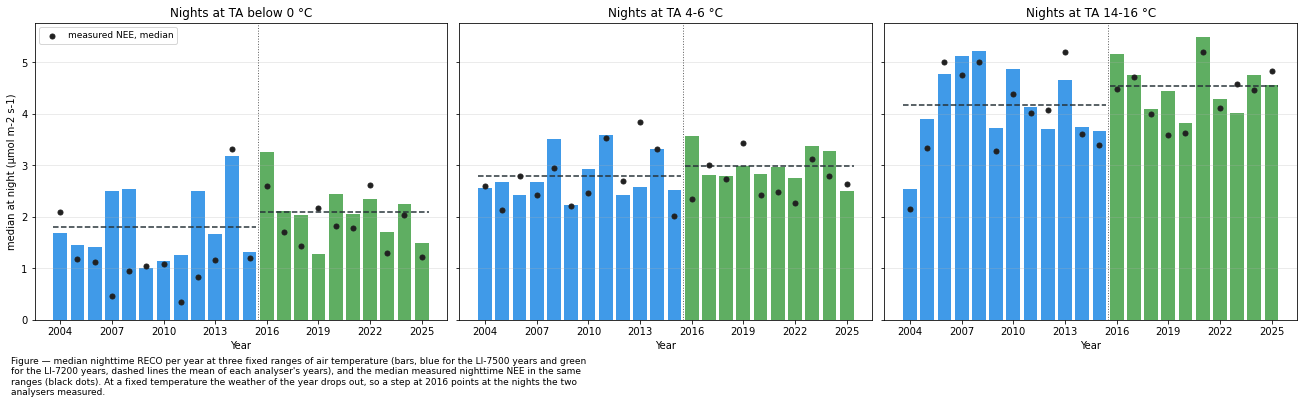

In [30]:
fig, axs = plt.subplots(1, len(FIXED_TA), figsize=(18, 5.5), dpi=72, sharey=True, layout="constrained")
_c = fixed['analyser'].map(ERA_COLORS)
for _ax, _label in zip(axs, FIXED_TA):
    _ax.bar(fixed.index, fixed[f"RECO, {_label}"], color=_c, alpha=0.85)
    _ax.scatter(fixed.index, fixed[f"NEE, {_label}"], color='#212121', s=25, zorder=5,
                label="measured NEE, median")
    for _name, _col in ERA_COLORS.items():
        _x = fixed.loc[fixed['analyser'] == _name, f"RECO, {_label}"]
        _ax.hlines(_x.mean(), _x.index.min() - 0.4, _x.index.max() + 0.4, color='#263238', lw=1.5, ls='--')
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.axvline(2015.5, color='#616161', lw=1, ls=':')
    _ax.set_title(f"Nights at TA {_label}")
    _ax.set_xlabel("Year")
    _ax.grid(alpha=0.3, axis='y')
    year_axis(_ax)
axs[0].set_ylabel(f"median at night ({units})")
axs[0].legend(fontsize=9, loc='upper left')
figcap(fig, "median nighttime RECO per year at three fixed ranges of air temperature (bars, blue for the "
            "LI-7500 years and green for the LI-7200 years, dashed lines the mean of each analyser's years), "
            "and the median measured nighttime NEE in the same ranges (black dots). At a fixed temperature "
            "the weather of the year drops out, so a step at 2016 points at the nights the two analysers "
            "measured.")
fig.show()

## 📋 Table: temperature response per analyser

In [31]:
_rows = {}
for _name, _sel in ERAS:
    _f = fixed[fixed['analyser'] == _name]
    _row = {'median E0 (K)': _f['E0 (K)'].median(), f"median Rref ({units})": _f[f"median Rref ({units})"].median()}
    _s = df[is_night & _sel(df.index)]
    for _label, (_lo, _hi) in FIXED_TA.items():
        _in = in_range(_s[TA], _lo, _hi)
        _row[f"RECO, {_label}"] = _s.loc[_in, varname].median()
        _row[f"NEE, {_label}"] = _s.loc[_in, nee_measured].median()
    _rows[f"{_name} years"] = _row
responses = pd.DataFrame.from_dict(_rows, orient='index')
responses.loc['difference (LI-7200 minus LI-7500)'] = responses.iloc[1] - responses.iloc[0]
responses.loc['ratio (LI-7500 / LI-7200)'] = responses.iloc[0] / responses.iloc[1]
display(styled(responses, caption=f"the model parameters (median over the years) and the medians of nighttime RECO "
                                  f"and of measured nighttime NEE at fixed air temperatures, in {units}, over all "
                                  f"years of each analyser, with their difference and ratio",
               fmt={c: ("{:.0f}" if c == 'median E0 (K)' else "{:+.2f}") for c in responses.columns},
               cmap=None).format("{:.2f}", subset=pd.IndexSlice[['ratio (LI-7500 / LI-7200)'], :]))

Table — the model parameters (median over the years) and the medians of nighttime RECO and of
measured nighttime NEE at fixed air temperatures, in µmol m-2 s-1, over all years of each analyser,
with their difference and ratio



,median E0 (K),median Rref (µmol m-2 s-1),"RECO, below 0 °C","NEE, below 0 °C","RECO, 4-6 °C","NEE, 4-6 °C","RECO, 14-16 °C","NEE, 14-16 °C"
LI-7500 years,105,+4.16,+1.57,+1.06,+2.86,+2.76,+4.15,+4.09
LI-7200 years,129,+4.57,+2.06,+1.66,+2.94,+2.71,+4.51,+4.30
difference (LI-7200 minus LI-7500),24,+0.41,+0.49,+0.60,+0.08,-0.06,+0.36,+0.20
ratio (LI-7500 / LI-7200),0.81,0.91,0.76,0.64,0.97,1.02,0.92,0.95


</br>

# The two analysers in parallel

From 11 January 2016 to 12 December 2017 both analysers measured, and each analyser's `NEE` was
partitioned on its own. The merged record uses the LI-7200; this section reads both per-analyser
records over these two years. Both models are evaluated with the same air temperature, so a
difference between them comes from the nighttime `NEE` each was fitted on.

In [32]:
_cols = [varname, varname_dt, gppname, nee_measured, nee_flag]
par = pd.concat({'IRGA75': pd.read_parquet(Path(DATADIR) / FILE_IRGA75, columns=_cols),
                 'IRGA72': pd.read_parquet(Path(DATADIR) / FILE_IRGA72, columns=_cols)}, axis=1)
par = par.loc[PARALLEL[0]:PARALLEL[1] + ' 23:45']
par_night = df_full.loc[par.index, NIGHTTIME].eq(1)
par_ta = df_full.loc[par.index, TA]
assert par.xs(varname, axis=1, level=1).notna().all().all(), "RECO missing in the parallel period"
print(f"Parallel period: {par.index[0]} -> {par.index[-1]} ({len(par):,} half-hours)")
for _a in ('IRGA75', 'IRGA72'):
    print(f"{_a} nights measured: {par.loc[par_night, (_a, nee_flag)].eq(0).mean() * 100:.1f} %")

Parallel period: 2016-01-11 00:15:00 -> 2017-12-12 23:45:00 (33,696 half-hours)
IRGA75 nights measured: 28.4 %
IRGA72 nights measured: 34.7 %


## 📋 Table: both analysers in the parallel period

In [33]:
_rows = {}
for _label, _col in ((f"RECO, nighttime method ({units_sum})", varname),
                     (f"RECO, daytime method ({units_sum})", varname_dt),
                     (f"GPP, nighttime method ({units_sum})", gppname)):
    _rows[_label] = {'LI-7500': to_gc(par[('IRGA75', _col)]), 'LI-7200': to_gc(par[('IRGA72', _col)])}
for _label, _mask in (("nights measured (%)", par_night),
                      ("nights below 0 °C measured (%)", par_night & (par_ta < 0)),
                      ("nights 0 °C and above measured (%)", par_night & (par_ta >= 0))):
    _rows[_label] = {_n: par.loc[_mask, (_a, nee_flag)].eq(0).mean() * 100
                     for _n, _a in (('LI-7500', 'IRGA75'), ('LI-7200', 'IRGA72'))}
_cold = par_night & (par_ta < 0)
for _n, _a in (('LI-7500', 'IRGA75'), ('LI-7200', 'IRGA72')):
    _rows.setdefault(f"median measured NEE, nights below 0 °C ({units})", {})[_n] = \
        par.loc[_cold, (_a, nee_measured)].median()
    _rows.setdefault(f"median RECO, nights below 0 °C ({units})", {})[_n] = par.loc[_cold, (_a, varname)].median()
parallel = pd.DataFrame.from_dict(_rows, orient='index')
parallel['LI-7500 minus LI-7200'] = parallel['LI-7500'] - parallel['LI-7200']
parallel['LI-7500 / LI-7200 (%)'] = parallel['LI-7500'] / parallel['LI-7200'] * 100
parallel.index.name = 'quantity'
display(styled(parallel, caption=f"RECO and GPP summed over {PARALLEL[0]} to {PARALLEL[1]} for both analysers, "
                                 f"each partitioned from its own NEE, with the share of nights each analyser "
                                 f"measured and the medians of measured nighttime NEE and of RECO on cold "
                                 f"nights. A negative difference is less by the LI-7500",
               fmt="{:.1f}", subset=['LI-7500 minus LI-7200'], cmap='RdBu_r', center=True))

Table — RECO and GPP summed over 2016-01-11 to 2017-12-12 for both analysers, each partitioned from
its own NEE, with the share of nights each analyser measured and the medians of measured nighttime
NEE and of RECO on cold nights. A negative difference is less by the LI-7500



,LI-7500,LI-7200,LI-7500 minus LI-7200,LI-7500 / LI-7200 (%)
quantity,,,,
"RECO, nighttime method (gC m-2)",2535.9,3253.1,-717.3,78.0
"RECO, daytime method (gC m-2)",3038.6,3671.8,-633.2,82.8
"GPP, nighttime method (gC m-2)",3218.7,3386.0,-167.3,95.1
nights measured (%),28.4,34.7,-6.2,82.0
nights below 0 °C measured (%),26.4,39.5,-13.1,66.8
nights 0 °C and above measured (%),29.4,34.6,-5.3,84.8
"median measured NEE, nights below 0 °C (µmol m-2 s-1)",1.0,1.9,-1.0,50.8
"median RECO, nights below 0 °C (µmol m-2 s-1)",1.7,2.5,-0.7,69.5


## 📊 Plot: cumulative RECO of both analysers in the parallel period

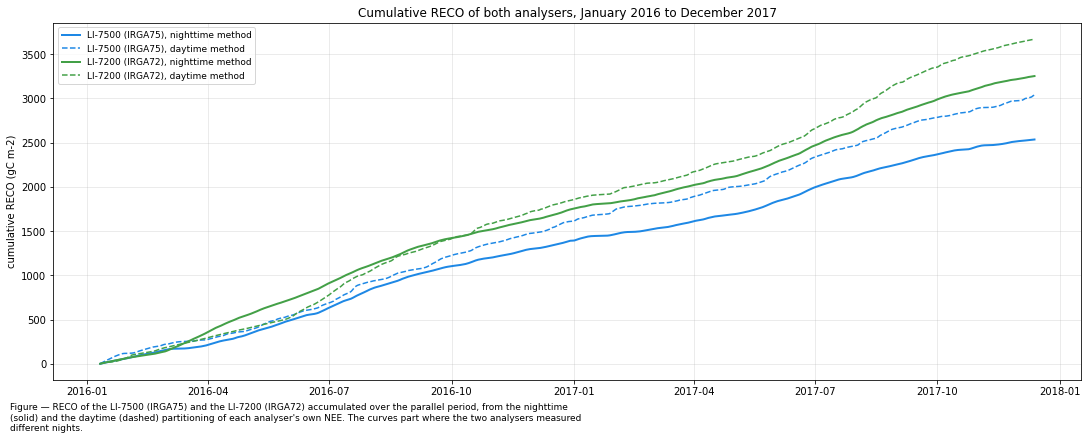

In [34]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
for _a, _name, _c in (('IRGA75', 'LI-7500', '#1E88E5'), ('IRGA72', 'LI-7200', '#43A047')):
    ax.plot(par.index, par[(_a, varname)].cumsum() * UMOL_TO_GC, color=_c, lw=2,
            label=f"{_name} ({_a}), nighttime method")
    ax.plot(par.index, par[(_a, varname_dt)].cumsum() * UMOL_TO_GC, color=_c, lw=1.5, ls='--',
            label=f"{_name} ({_a}), daytime method")
ax.set_ylabel(f"cumulative RECO ({units_sum})")
ax.set_title("Cumulative RECO of both analysers, January 2016 to December 2017")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
figcap(fig, "RECO of the LI-7500 (IRGA75) and the LI-7200 (IRGA72) accumulated over the parallel period, from "
            "the nighttime (solid) and the daytime (dashed) partitioning of each analyser's own NEE. The "
            "curves part where the two analysers measured different nights.")
fig.show()

## 📊 Plot: monthly RECO of both analysers and their difference

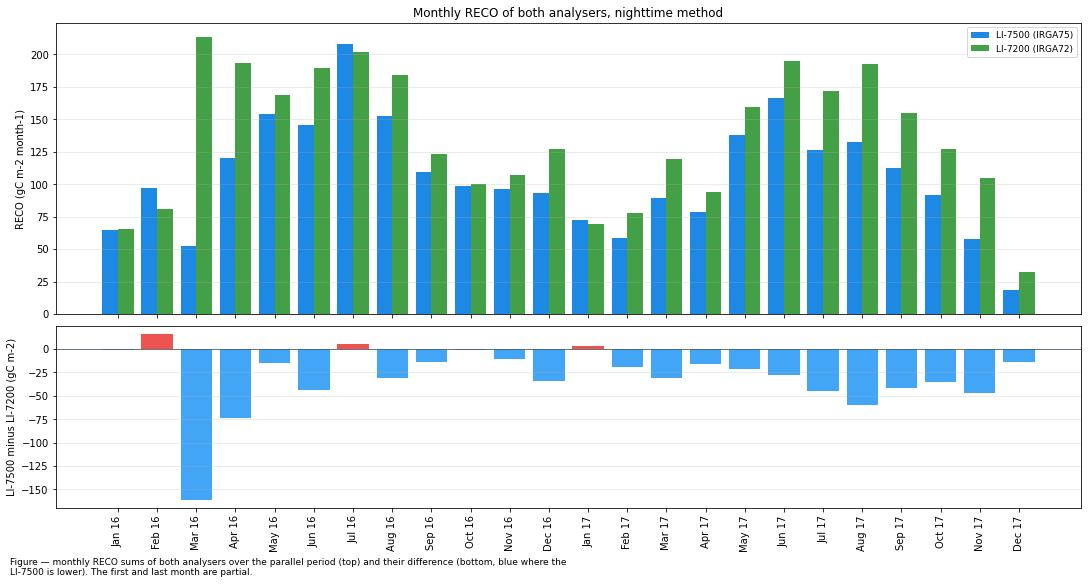

In [35]:
_m = par.xs(varname, axis=1, level=1).resample('MS').sum() * UMOL_TO_GC
_x = np.arange(len(_m))
fig, axs = plt.subplots(2, 1, figsize=(15, 8), dpi=72, sharex=True, layout="constrained", height_ratios=[1.6, 1])
axs[0].bar(_x - 0.2, _m['IRGA75'], width=0.4, color='#1E88E5', label="LI-7500 (IRGA75)")
axs[0].bar(_x + 0.2, _m['IRGA72'], width=0.4, color='#43A047', label="LI-7200 (IRGA72)")
axs[0].set_ylabel(f"RECO ({units_sum} month-1)")
axs[0].set_title("Monthly RECO of both analysers, nighttime method")
axs[0].legend(fontsize=9)
_diff = _m['IRGA75'] - _m['IRGA72']
axs[1].bar(_x, _diff, color=np.where(_diff < 0, '#42A5F5', '#EF5350'))
axs[1].axhline(0, color='#455A64', lw=0.8)
axs[1].set_ylabel(f"LI-7500 minus LI-7200 ({units_sum})")
axs[1].set_xticks(_x)
axs[1].set_xticklabels([f"{t:%b %y}" for t in _m.index], rotation=90)
for _ax in axs:
    _ax.grid(alpha=0.3, axis='y')
figcap(fig, "monthly RECO sums of both analysers over the parallel period (top) and their difference "
            "(bottom, blue where the LI-7500 is lower). The first and last month are partial.")
fig.show()

## 📊 Plot: nighttime RECO and NEE of both analysers by temperature

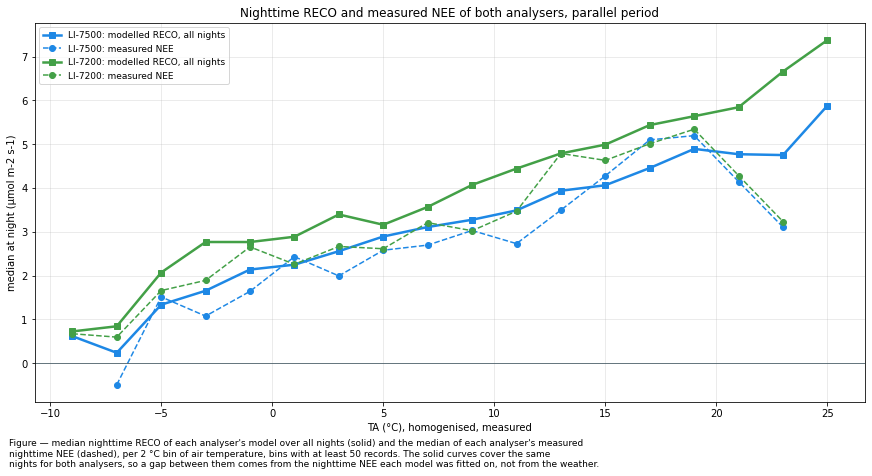

In [36]:
_bins = np.arange(-12, 27, TA_BIN_WIDTH)
fig, ax = plt.subplots(figsize=(12, 6.5), dpi=72, layout="constrained")
for _a, _name, _c in (('IRGA75', 'LI-7500', '#1E88E5'), ('IRGA72', 'LI-7200', '#43A047')):
    _r = par.loc[par_night, (_a, varname)]
    ax.plot(*binned_median(par_ta[par_night], _r, _bins), color=_c, lw=2.5, marker='s',
            label=f"{_name}: modelled RECO, all nights")
    _e = par.loc[par_night, (_a, nee_measured)].dropna()
    ax.plot(*binned_median(par_ta.loc[_e.index], _e, _bins), color=_c, lw=1.5, ls='--', marker='o',
            label=f"{_name}: measured NEE")
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_xlabel("TA (°C), homogenised, measured")
ax.set_ylabel(f"median at night ({units})")
ax.set_title("Nighttime RECO and measured NEE of both analysers, parallel period")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
figcap(fig, f"median nighttime RECO of each analyser's model over all nights (solid) and the median of "
            f"each analyser's measured nighttime NEE (dashed), per {TA_BIN_WIDTH} °C bin of air temperature, "
            f"bins with at least {MIN_RECORDS_BIN} records. The solid curves cover the same nights for both "
            f"analysers, so a gap between them comes from the nighttime NEE each model was fitted on, not "
            f"from the weather.")
fig.show()

</br>

# Heatmap plots

## Half-hourly

### 📊 Plot: heatmap of the half-hourly values

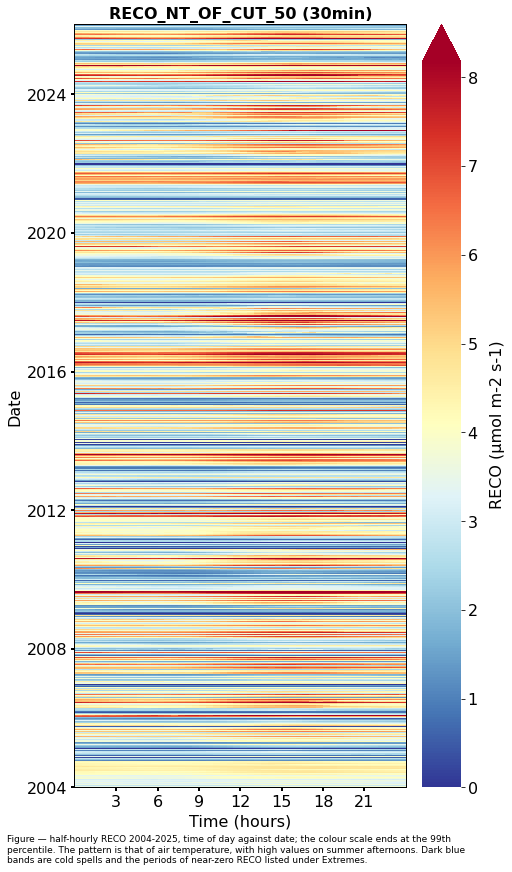

In [37]:
_hi = series.quantile(0.99)
fig, ax = plt.subplots(figsize=(7, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapDateTime(series=series).plot(ax=ax, cmap='RdYlBu_r', vmin=0, vmax=_hi,
                                                cb_extend='max', zlabel=xlabel)
figcap(fig, f"half-hourly RECO {FIRST_YEAR}-{LAST_YEAR}, time of day against date; the colour scale ends at "
            f"the 99th percentile. The pattern is that of air temperature, with high values on summer "
            f"afternoons. Dark blue bands are cold spells and the periods of near-zero RECO listed under "
            f"Extremes.")

## Monthly

### 📊 Plot: monthly sums and their ranks

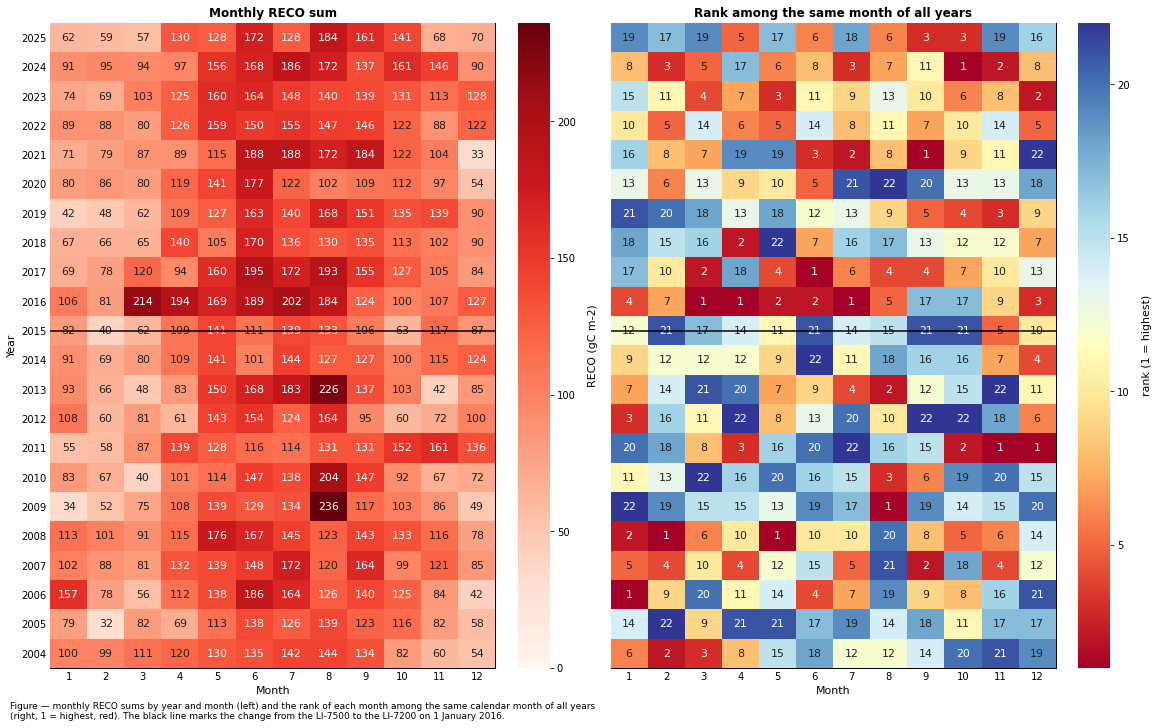

In [38]:
fig, axs = plt.subplots(ncols=2, figsize=(16, 10), dpi=72, sharey=True, layout="constrained")
_style = dv.plotting.FormatStyle(axlabel_fontsize=11, ticks_fontsize=10)
_long = monthly_by_number.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=axs[0], cmap='Reds', vmin=0, vmax=_long['z'].max(), xlabel="Month", ylabel="Year",
    zlabel=f"RECO ({units_sum})", show_values=True, cb_labelsize=10, format_style=_style)
# Rank 1 is the month of highest RECO among the same calendar month of all years.
_ranks = monthly_by_number.rank(axis=0, ascending=False).stack().rename('z').reset_index()
_ranks.columns = ['YEAR', 'MONTH', 'z']
dv.plotting.HeatmapXYZ(x=_ranks['MONTH'], y=_ranks['YEAR'], z=_ranks['z']).plot(
    ax=axs[1], cmap='RdYlBu', xlabel="Month", ylabel="", zlabel="rank (1 = highest)",
    show_values=True, cb_labelsize=10, format_style=_style)
for _ax, _title in zip(axs, ["Monthly RECO sum", "Rank among the same month of all years"]):
    _ax.set_title(_title, fontsize=12, fontweight='bold', color='black')
    _ax.axhline(2015.5, color='black', lw=1.5, zorder=200)
figcap(fig, f"monthly RECO sums by year and month (left) and the rank of each month among the same "
            f"calendar month of all years (right, 1 = highest, red). The black line marks the change "
            f"from the LI-7500 to the LI-7200 on 1 January 2016.")

## Anomaly by year and month

### 📊 Plot: anomaly by year and month

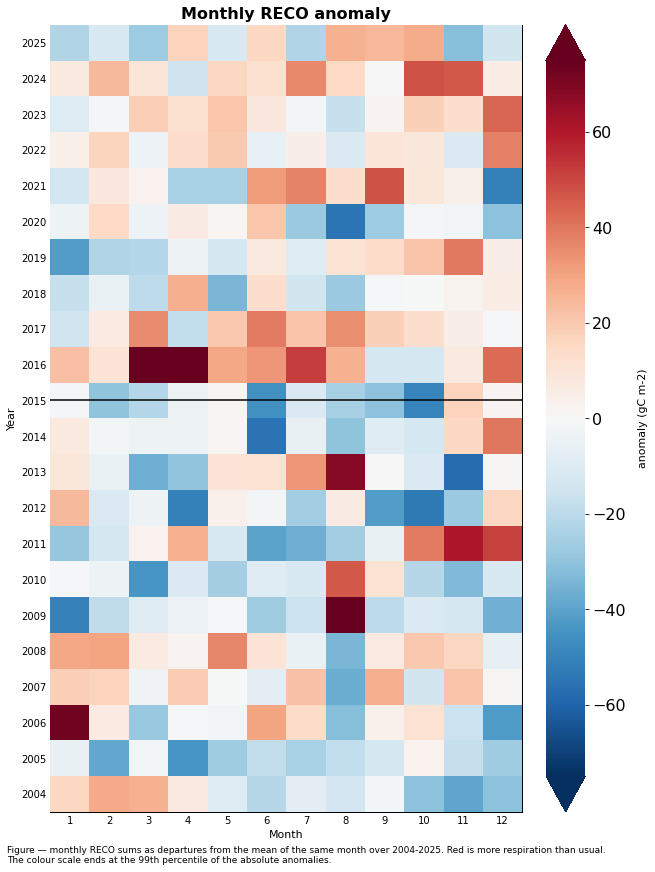

In [39]:
_anom = monthly_by_number - monthly_by_number.loc[REFERENCE_START_YEAR:REFERENCE_END_YEAR].mean()
_long = _anom.stack().rename('z').reset_index()
_long.columns = ['YEAR', 'MONTH', 'z']
_absmax = _long['z'].abs().quantile(0.99)
fig, ax = plt.subplots(figsize=(9, 12), dpi=72, layout="constrained")
dv.plotting.HeatmapXYZ(x=_long['MONTH'], y=_long['YEAR'], z=_long['z']).plot(
    ax=ax, cmap='RdBu_r', vmin=-_absmax, vmax=_absmax, cb_extend='both', xlabel="Month", ylabel="Year",
    zlabel=f"anomaly ({units_sum})",
    format_style=dv.plotting.FormatStyle(title=f"Monthly {var} anomaly", axlabel_fontsize=11, ticks_fontsize=10))
ax.axhline(2015.5, color='black', lw=1.5, zorder=200)
figcap(fig, f"monthly RECO sums as departures from the mean of the same month over "
            f"{REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. Red is more respiration than usual. The colour "
            f"scale ends at the 99th percentile of the absolute anomalies.")

</br>

# Anomalies and trends

## Per year

### 📊 Plot: yearly anomalies

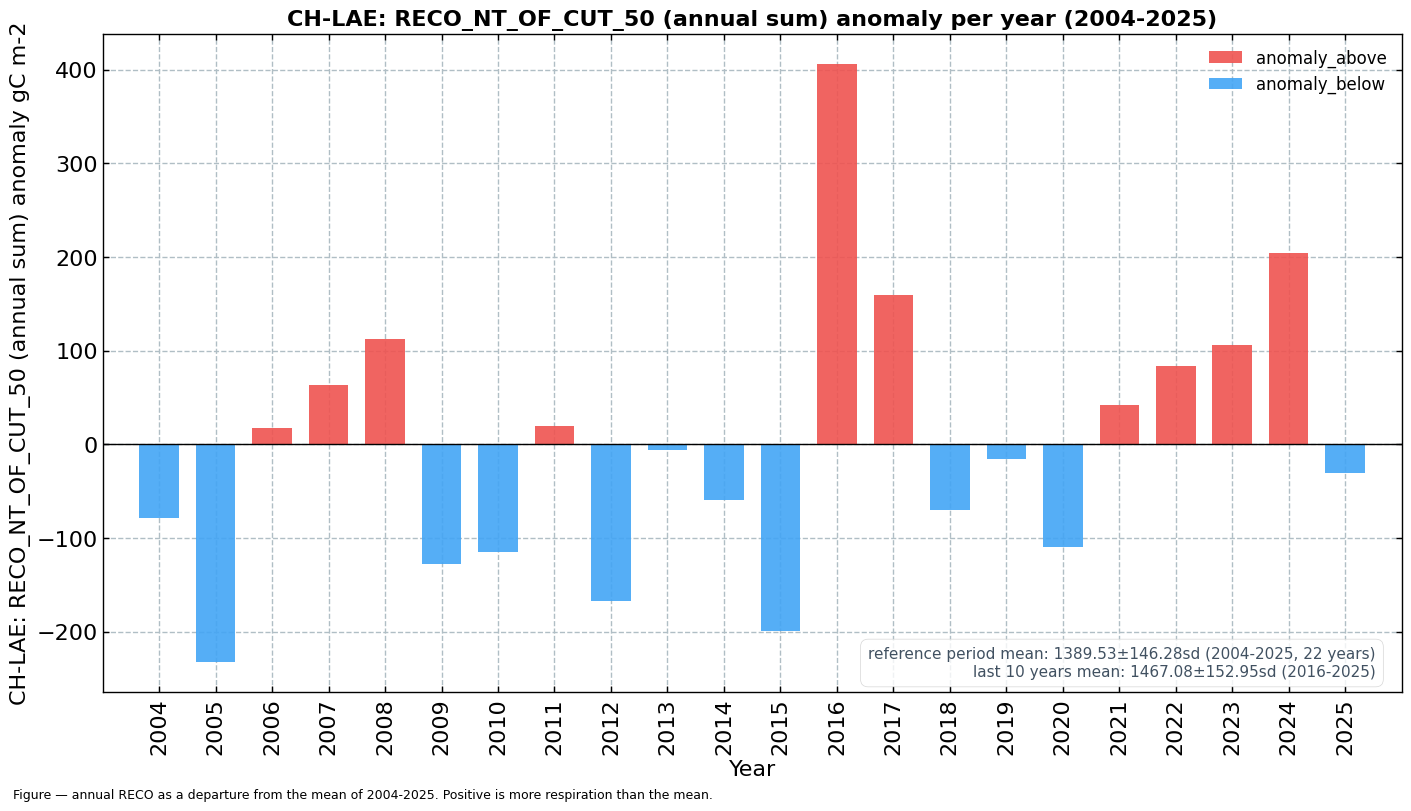

In [40]:
_anomalies_year = LongtermAnomaliesYear(series=yt.rename(varname),
                                        series_label=f"CH-LAE: {varname} (annual sum)",
                                        series_units=units_sum,
                                        reference_start_year=REFERENCE_START_YEAR,
                                        reference_end_year=REFERENCE_END_YEAR)
_anomalies_year.plot()
figcap(_anomalies_year.fig,
       f"annual RECO as a departure from the mean of {REFERENCE_START_YEAR}-{REFERENCE_END_YEAR}. Positive is "
       f"more respiration than the mean.")

## Trends

A trend over the whole record crosses the change of analyser. It is therefore given three ways:
over all years, over the LI-7200 years alone, and with a step at 2016 removed, so that a trend
carried by the step alone can be told apart.

### 📋 Table: trends of the annual sums

In [41]:
def _trend_row(s):
    _fit = trend(s.dropna())
    return {"trend (per decade)": _fit['slope'], "lower 95 %": _fit['low'], "upper 95 %": _fit['high'],
            "p": _fit['pvalue'], "years": int(s.notna().sum())}


_rows = {}
for _c, _label in ((f"RECO ({units_sum})", f"RECO, NT ({units_sum})"), ("ROB", f"RECO, ROB ({units_sum})"),
                   ("DT", f"RECO, DT ({units_sum})"), ("GPP (NT)", f"GPP, NT ({units_sum})"),
                   ("RECO / GPP", "RECO / GPP (%)")):
    _s = annual[_c] * (100 if _c == "RECO / GPP" else 1)
    _first = int(_s.first_valid_index())
    _rows[(_label, f"all years, {_first}-{LAST_YEAR}")] = _trend_row(_s)
    _rows[(_label, f"LI-7200 years, 2016-{LAST_YEAR}")] = _trend_row(_s.loc[2016:])
    _rows[(_label, "all years, step at 2016 removed")] = _trend_row(
        _s - _s.groupby(annual['analyser']).transform('mean') + _s.mean())
trends = pd.DataFrame.from_dict(_rows, orient='index')
trends.index.names = ['flux', 'years']
_fmt = {c: ("{:.4f}" if c == "p" else "{:.0f}" if c == "years" else "{:+.1f}") for c in trends.columns}
display(styled(trends, caption="Theil-Sen trends of the annual sums per decade, in the units of each flux, with "
                               "their 95 % interval and Kendall p. Removing the step subtracts each analyser "
                               "period's own mean, so only the trend within the periods remains. The ratio "
                               "RECO / GPP is given in percent, its trend in percentage points per decade",
               fmt=_fmt, cmap=None))

Table — Theil-Sen trends of the annual sums per decade, in the units of each flux, with their 95 %
interval and Kendall p. Removing the step subtracts each analyser period's own mean, so only the
trend within the periods remains. The ratio RECO / GPP is given in percent, its trend in percentage
points per decade



### 📊 Plot: annual sums and their trends

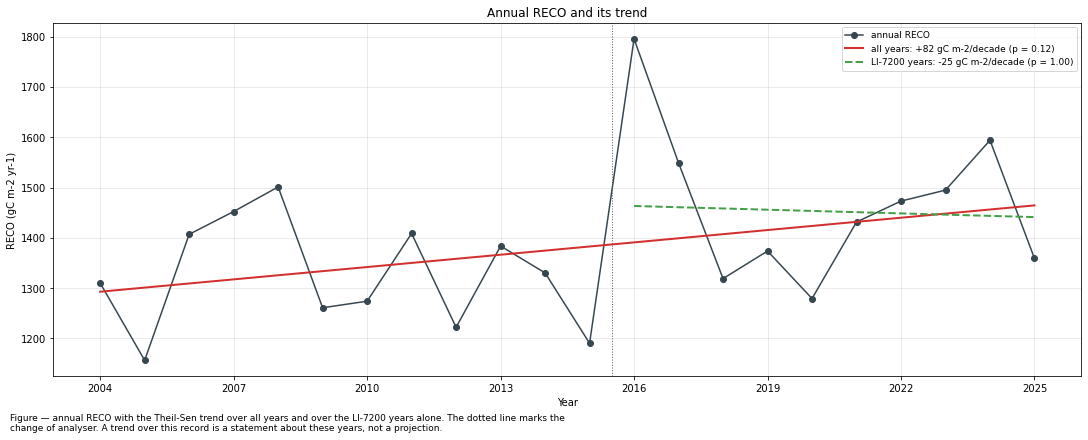

In [42]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
ax.plot(yt.index, yt, marker='o', color='#37474F', lw=1.5, label="annual RECO")
_fit = trend(yt)
ax.plot(_fit['fit'].index, _fit['fit'], color='#D32F2F', lw=2,
        label=f"all years: {_fit['slope']:+.0f} {units_sum}/decade (p = {_fit['pvalue']:.2f})")
_fit72 = trend(yt.loc[2016:])
ax.plot(_fit72['fit'].index, _fit72['fit'], color='#43A047', lw=2, ls='--',
        label=f"LI-7200 years: {_fit72['slope']:+.0f} {units_sum}/decade (p = {_fit72['pvalue']:.2f})")
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_xlabel("Year")
ax.set_ylabel(f"RECO ({units_sum} yr-1)")
ax.set_title("Annual RECO and its trend")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
year_axis(ax)
figcap(fig, "annual RECO with the Theil-Sen trend over all years and over the LI-7200 years alone. The "
            "dotted line marks the change of analyser. A trend over this record is a statement about "
            "these years, not a projection.")
fig.show()

</br>

# Cumulative plot

## 📊 Plot: cumulative RECO per year

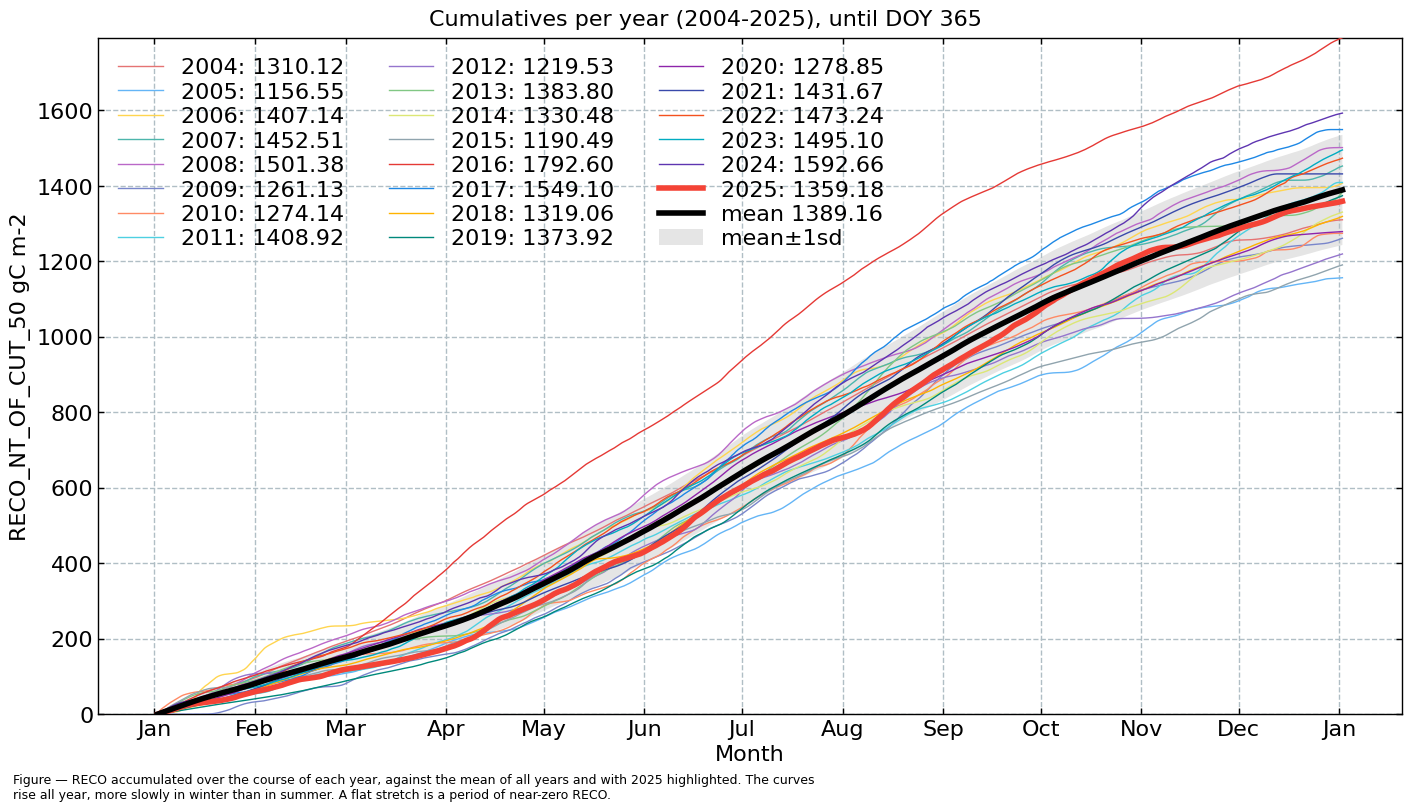

In [43]:
_cumulative = CumulativeYear(
    series=(series * UMOL_TO_GC).rename(varname),
    series_units=units_sum,
    start_year=FIRST_YEAR,
    end_year=LAST_YEAR,
    show_reference=True,
    excl_years_from_reference=None,
    highlight_year=LAST_YEAR)
_cumulative.plot(highlight_year_color='#F44336')
figcap(_cumulative.fig,
       f"RECO accumulated over the course of each year, against the mean of all years and with {LAST_YEAR} "
       f"highlighted. The curves rise all year, more slowly in winter than in summer. A flat stretch "
       f"is a period of near-zero RECO.")

</br>

# Distributions

## 📊 Plot: distribution per year

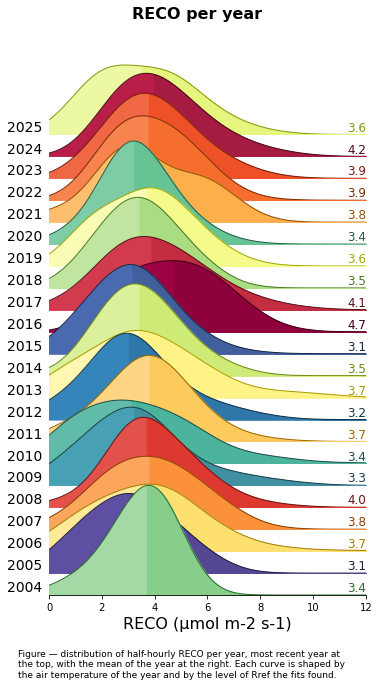

In [44]:
rp = dv.plotting.RidgeLinePlot(series=series)
rp.plot(
    how='yearly',
    kd_kwargs=None,  # params from scikit KernelDensity as dict
    xlim=[0, 12],  # min/max as list
    ylim=None,  # min/max as list
    hspace=-0.8,  # overlap between years
    fig_width=5,
    fig_height=9,
    shade_percentile=0.5,
    show_mean_line=False,
    format_style=dv.plotting.FormatStyle(xlabel=xlabel, title=f"{var} per year"),
    fig_dpi=72,
    showplot=True,
    ascending=False
)
figcap(rp.fig, "distribution of half-hourly RECO per year, most recent year at the top, with the mean of "
               "the year at the right. Each curve is shaped by the air temperature of the year and by the "
               "level of Rref the fits found.")

</br>

# End of notebook

In [45]:
NOTEBOOK_END = datetime.now()
print(f"Finished. {NOTEBOOK_END:%Y-%m-%d %H:%M:%S}")
print(f"Runtime: {str(NOTEBOOK_END - NOTEBOOK_START).split('.')[0]} (h:mm:ss)")

Finished. 2026-10-31 16:50:21
Runtime: 0:00:09 (h:mm:ss)
